# FINAL PROJECT: Are Airline Reliability Rankings Misleading?

### **Introduction & Strategic Objectives**

**Business question:** How much of an airline's reliability is associated with operational performance versus the airports and routes it serves? How do flight volume and statistical uncertainty change how we interpret rankings?

**Audience:** United Airlines executives.

**Goal:** Test whether overall airline reliability rankings tell the full story, then use the findings to support a repeatable **monthly reliability and competitive assessment** for leadership.

**Analysis:** (1) overall airline performance, (2) airport-network exposure, (3) flight volume and ranking confidence, and (4) shared-route competitor comparisons.

**Deliverable:** A monthly executive report with performance scorecards, historical comparisons, targeted areas to monitor and evidence-based recommendations. January 2025 is the only available month, so past-period comparisons must remain unavailable until verified data is added.

### **Data Sources & Analytical Approach**

The analysis uses data from the U.S. Department of Transportation's Bureau of Transportation Statistics (BTS), covering 539,747 scheduled domestic flights in January 2025 across 14 reporting airlines and 329 origin airports.

It looks at which airlines are most reliable and whether the airports and routes they serve affect their rankings. The goal is to help airline executives understand where they are falling behind competitors and where they can improve.

| Metric | Definition |
|---|---|
| On-time arrival rate | Percentage of completed flights arriving less than 15 minutes late |
| Cancellation rate | Percentage of scheduled flights canceled |
| Average arrival delay | Average number of minutes flights arrive early or late |
| Route-adjusted performance | How an airline performs compared with competitors flying the same routes |

In [1]:
# Locate the BTS January 2025 file. Download instructions are in the README.
# Order: extracted CSV in the project folder, then the original zip, then a Colab upload.
from pathlib import Path

CSV_NAME = "On_Time_Reporting_Carrier_On_Time_Performance_(1987_present)_2025_1.csv"
ZIP_NAME = "On_Time_Reporting_Carrier_On_Time_Performance_1987_present_2025_1.zip"
CANDIDATES = [
    Path("On_Time_Reporting_Carrier_On_Time_Performance_1987_present_2025_1") / CSV_NAME,
    Path(CSV_NAME),
    Path(ZIP_NAME),
]
data_source = next((p for p in CANDIDATES if p.exists()), None)

if data_source is None:
    try:
        from google.colab import files
        uploaded = files.upload()
        data_source = Path(next(iter(uploaded)))
    except ImportError:
        raise FileNotFoundError(
            "BTS data not found. Download the January 2025 file (see README) into this folder."
        )
print("Data source:", data_source)

Data source: On_Time_Reporting_Carrier_On_Time_Performance_1987_present_2025_1/On_Time_Reporting_Carrier_On_Time_Performance_(1987_present)_2025_1.csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import zipfile

if data_source.suffix == ".zip":
    with zipfile.ZipFile(data_source) as z:
        csv_name = next(name for name in z.namelist() if name.endswith(".csv"))
        with z.open(csv_name) as f:
            df = pd.read_csv(f, low_memory=False)
else:
    df = pd.read_csv(data_source, low_memory=False)

# Review dataset size
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# Assertions: the expected BTS file was loaded
assert df.shape[0] == 539_747, "Unexpected row count: is this the January 2025 file?"
assert df["FlightDate"].min().startswith("2025-01") and df["FlightDate"].max().startswith("2025-01")
assert df.duplicated().sum() == 0, "Duplicate rows found"

df.head()

Rows: 539747
Columns: 110


,Year,Quarter,Month,DayofMonth,DayOfWeek,FlightDate,Reporting_Airline,DOT_ID_Reporting_Airline,IATA_CODE_Reporting_Airline,Tail_Number,...,Div4TailNum,Div5Airport,Div5AirportID,Div5AirportSeqID,Div5WheelsOn,Div5TotalGTime,Div5LongestGTime,Div5WheelsOff,Div5TailNum,Unnamed: 109
0,2025,1,1,1,3,2025-01-01,AA,19805,AA,N104NN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2025,1,1,2,4,2025-01-02,AA,19805,AA,N110AN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2025,1,1,3,5,2025-01-03,AA,19805,AA,N106NN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2025,1,1,4,6,2025-01-04,AA,19805,AA,N117AN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2025,1,1,5,7,2025-01-05,AA,19805,AA,N104NN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Selecting Data & Checking for Missing Values

Selected 10 columns from the dataset based on the information needed to compare airline performance, including airlines, airports, routes, delays and cancellations. Created route names and checked for missing data.



In [3]:

# Select columns relevant to our analysis
columns = [
    "FlightDate",
    "Reporting_Airline",
    "Origin",
    "Dest",
    "CRSDepTime",
    "Distance",
    "ArrDelay",
    "ArrDel15",
    "Cancelled",
    "Diverted"
]

flights = df[columns].copy()

# Create a route identifier
flights["Route"] = flights["Origin"] + "-" + flights["Dest"]

# Check for missing values
print("Total flights:", len(flights))
print("\nMissing values by column:")
print(flights.isnull().sum())


Total flights: 539747

Missing values by column:
FlightDate               0
Reporting_Airline        0
Origin                   0
Dest                     0
CRSDepTime               0
Distance                 0
ArrDelay             17478
ArrDel15             17478
Cancelled                0
Diverted                 0
Route                    0
dtype: int64


Categorizing Flight Performance

Grouped flights into completed, on-time and delayed categories based on their arrival times. Kept canceled and diverted flights separate, then counted the number of flights in each category.


In [4]:

# Identify flights with valid arrival-delay data
flights["Completed"] = (
    (flights["Cancelled"] == 0) &
    (flights["Diverted"] == 0) &
    (flights["ArrDelay"].notna())
)

# Identify on-time arrivals (less than 15 minutes late)
flights["OnTime"] = (
    flights["Completed"] &
    (flights["ArrDelay"] < 15)
)

# Identify flights arriving 15+ minutes late
flights["Delayed"] = (
    flights["Completed"] &
    (flights["ArrDelay"] >= 15)
)

# Summarize flight outcomes
print("Total flights:", len(flights))
print("Completed flights:", flights["Completed"].sum())
print("On-time arrivals:", flights["OnTime"].sum())
print("Delayed arrivals:", flights["Delayed"].sum())
print("Cancelled flights:", int(flights["Cancelled"].sum()))
print("Diverted flights:", int(flights["Diverted"].sum()))

# Assertions: every flight falls into exactly one outcome
assert flights["Completed"].sum() + flights["Cancelled"].sum() + flights["Diverted"].sum() == len(flights)
assert flights["OnTime"].sum() + flights["Delayed"].sum() == flights["Completed"].sum()
assert flights.loc[flights["Cancelled"] == 1, "ArrDelay"].isna().all(), "Cancelled flights should have no arrival delay"


Total flights: 539747
Completed flights: 522269
On-time arrivals: 424139
Delayed arrivals: 98130
Cancelled flights: 16312
Diverted flights: 1166


Initial Data Summary

The dataset includes 539,747 scheduled flights in January 2025. Flights were categorized as follows to ensure consistent comparisons across airlines:

- **On time:** Arrived less than 15 minutes after the scheduled arrival time, including early arrivals.
- **Delayed:** Arrived 15 or more minutes late.
- **Canceled or diverted:** Counted separately from completed flights.

| Metric | Result |
|---|---|
| Total flights | 539,747 |
| Completed flights | 522,269 |
| On-time arrival rate | 81.2% |
| Delayed arrival rate | 18.8% |
| Cancellation rate | 3.0% |
| Diversion rate | 0.2% |

On-time and delayed arrival rates are based on completed flights. Cancellation and diversion rates are based on all scheduled flights.


### **Analysis 1: Airline Reliability Benchmarking**

Comparing Airline Reliability

Compared airlines using on-time arrival rates, cancellation rates and average arrival delays to identify which performed best and worst in January 2025.


In [5]:

# Calculate performance metrics for each airline
airline_performance = flights.groupby("Reporting_Airline").agg(
    TotalFlights=("FlightDate", "count"),
    CompletedFlights=("Completed", "sum"),
    OnTimeFlights=("OnTime", "sum"),
    CancelledFlights=("Cancelled", "sum"),
    AverageArrivalDelay=("ArrDelay", "mean")
).reset_index()

# Calculate on-time and cancellation rates
airline_performance["OnTimeRate"] = (
    airline_performance["OnTimeFlights"] /
    airline_performance["CompletedFlights"] * 100
)

airline_performance["CancellationRate"] = (
    airline_performance["CancelledFlights"] /
    airline_performance["TotalFlights"] * 100
)

# Add full airline names
airline_names = {
    "AA": "American Airlines",
    "AS": "Alaska Airlines",
    "B6": "JetBlue Airways",
    "DL": "Delta Air Lines",
    "F9": "Frontier Airlines",
    "G4": "Allegiant Air",
    "HA": "Hawaiian Airlines",
    "MQ": "Envoy Air",
    "NK": "Spirit Airlines",
    "OH": "PSA Airlines",
    "OO": "SkyWest Airlines",
    "UA": "United Airlines",
    "WN": "Southwest Airlines",
    "YX": "Republic Airways"
}

airline_performance["Airline"] = (
    airline_performance["Reporting_Airline"]
    .map(airline_names)
)

# Rank airlines by on-time performance
airline_performance = airline_performance.sort_values(
    "OnTimeRate", ascending=False
)

# Create final summary table
performance_summary = airline_performance[
    [
        "Airline",
        "TotalFlights",
        "OnTimeRate",
        "CancellationRate",
        "AverageArrivalDelay"
    ]
].copy()

# Rename columns for readability
performance_summary.columns = [
    "Airline",
    "Total Flights",
    "On-Time Rate (%)",
    "Cancellation Rate (%)",
    "Average Arrival Delay (min)"
]
# Create a clear ranking based on on-time arrival rate
performance_summary = performance_summary.reset_index(drop=True)

# Add rank as the first column
performance_summary.insert(
    0, "On-Time Rank", range(1, len(performance_summary) + 1)
)

# Display the table without the extra index
display(
    performance_summary.round(2).style.hide(axis="index")
    .format({
        "Total Flights": "{:,.0f}",
        "On-Time Rate (%)": "{:.2f}%",
        "Cancellation Rate (%)": "{:.2f}%",
        "Average Arrival Delay (min)": "{:.2f}"
    })
)

On-Time Rank,Airline,Total Flights,On-Time Rate (%),Cancellation Rate (%),Average Arrival Delay (min)
1,Hawaiian Airlines,"6,690",86.45%,1.91%,6.04
2,Southwest Airlines,"105,307",84.79%,2.86%,-1.17
3,Republic Airways,"27,833",83.98%,4.02%,-2.29
4,Alaska Airlines,"18,163",82.42%,1.34%,-0.12
5,United Airlines,"62,007",82.37%,1.92%,1.29
6,Spirit Airlines,"17,544",81.92%,3.26%,0.65
7,Envoy Air,"21,890",81.57%,4.71%,4.81
8,American Airlines,"75,088",80.77%,3.73%,5.57
9,Delta Air Lines,"76,306",80.68%,2.80%,5.22
10,SkyWest Airlines,"65,036",79.12%,2.07%,7.94


Initial Findings

On-time arrival rates varied across the 14 airlines, ranging from the highest of 86.45% for Hawaiian Airlines to the lowest of 74.02% for Frontier. United ranked fifth at 82.37%, ahead of both American and Delta.

Cancellation rates also varied, with PSA Airlines reporting the highest rate at 9.00% and Allegiant the lowest at 1.27%.

These results show differences in airline reliability, but they don't tell us whether those differences are related to airline operations or the airports and routes each airline serves.


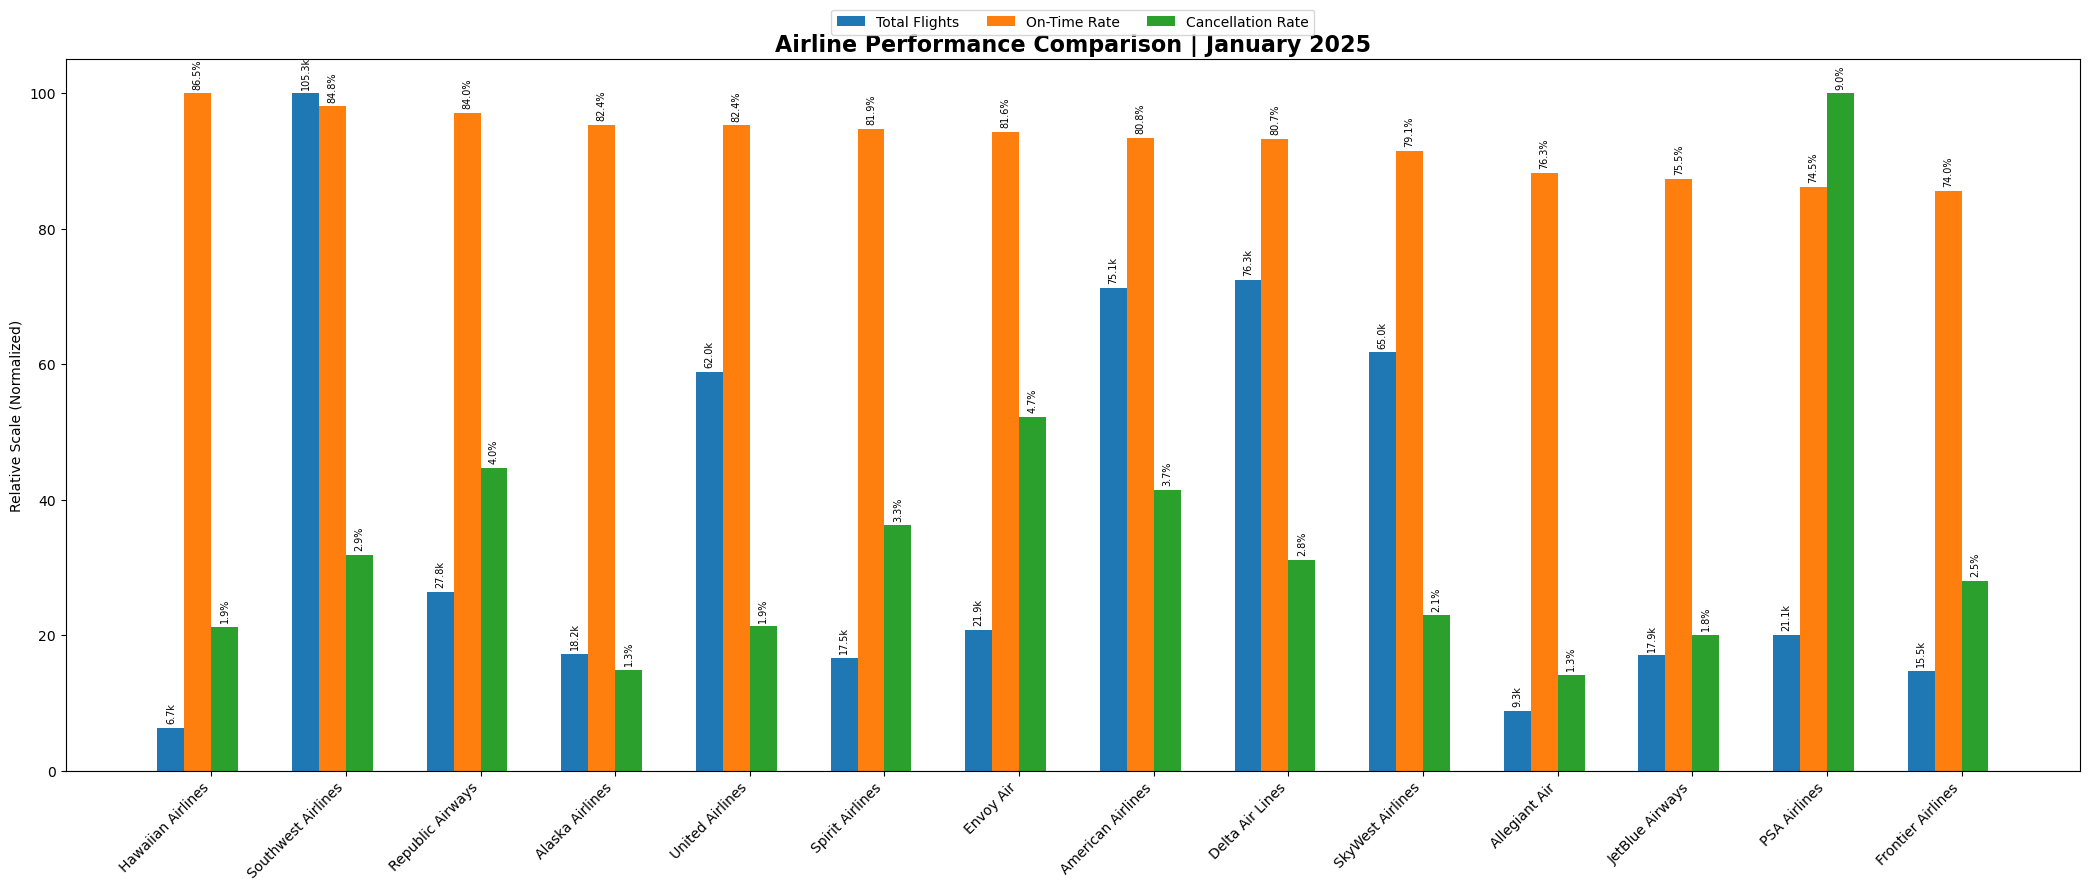

In [6]:

import matplotlib.pyplot as plt
import numpy as np

# Sort airlines by on-time arrival rate
chart_data = airline_performance.sort_values(
    "OnTimeRate", ascending=False
).copy()

# metrics to compare
metrics = [
    ("TotalFlights", "Total Flights"),
    ("OnTimeRate", "On-Time Rate"),
    ("CancellationRate", "Cancellation Rate")
]

# Normalize values for display
# Negative arrival delays are preserved in the original labels
normalized = {}

for column, label in metrics:
    values = chart_data[column]
    max_abs = values.abs().max()
    normalized[column] = values / max_abs * 100

# Set up grouped bar chart
x = np.arange(len(chart_data))
width = 0.2

fig, ax = plt.subplots(figsize=(21, 9))

for i, (column, label) in enumerate(metrics):
    positions = x + (i - 1.5) * width

    bars = ax.bar(
        positions,
        normalized[column],
        width,
        label=label
    )

    # Label bars with actual values
    for bar, value in zip(bars, chart_data[column]):
        if column == "TotalFlights":
            text = f"{value / 1000:.1f}k"
        elif column == "AverageArrivalDelay":
            text = f"{value:+.1f}m"
        else:
            text = f"{value:.1f}%"

        ax.annotate(
            text,
            (bar.get_x() + bar.get_width() / 2, bar.get_height()),
            xytext=(0, 3 if bar.get_height() >= 0 else -3),
            textcoords="offset points",
            ha="center",
            va="bottom" if bar.get_height() >= 0 else "top",
            rotation=90,
            fontsize=7
        )

ax.set_xticks(x)
ax.set_xticklabels(
    chart_data["Airline"],
    rotation=45,
    ha="right"
)

ax.set_ylabel("Relative Scale (Normalized)")
ax.set_title(
    "Airline Performance Comparison | January 2025",
    fontsize=16,
    fontweight="bold"
)

ax.axhline(0, color="gray", linewidth=0.8)
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, 1.08))

plt.tight_layout()
plt.show()


### **Analysis 2: Airport & Route Risk Assessment**

Airport Reliability Rankings

Compared airports with at least 1,000 scheduled flights in January 2025. Airports are ranked from highest to lowest on-time arrival rate, with flight volume and cancellation rates included for context.

In [7]:

# Calculate performance metrics for each departure airport
airport_performance = flights.groupby("Origin").agg(
    TotalFlights=("FlightDate", "count"),
    CompletedFlights=("Completed", "sum"),
    OnTimeFlights=("OnTime", "sum"),
    CancelledFlights=("Cancelled", "sum")
).reset_index()

# Calculate on-time and cancellation rates
airport_performance["OnTimeRate"] = (
    airport_performance["OnTimeFlights"] /
    airport_performance["CompletedFlights"] * 100
)

airport_performance["CancellationRate"] = (
    airport_performance["CancelledFlights"] /
    airport_performance["TotalFlights"] * 100
)

# Add full airport names using the original dataset
airport_names = (
    df[["Origin", "OriginCityName", "OriginStateName"]]
    .drop_duplicates(subset="Origin")
    .copy()
)

airport_names["Airport"] = (
    airport_names["OriginCityName"] +
    ", " +
    airport_names["OriginStateName"] +
    " (" +
    airport_names["Origin"] +
    ")"
)

airport_performance = airport_performance.merge(
    airport_names[["Origin", "Airport"]],
    on="Origin",
    how="left"
)

# Focus on airports with at least 1,000 scheduled flights
major_airports = airport_performance[
    airport_performance["TotalFlights"] >= 1000
].copy()

# Rank airports by highest on-time arrival rate
major_airports = major_airports.sort_values(
    "OnTimeRate", ascending=False
).reset_index(drop=True)

# Create final ranked table
airport_summary = major_airports[
    ["Airport", "TotalFlights", "OnTimeRate", "CancellationRate"]
].copy()

airport_summary.insert(
    0, "On-Time Rank", range(1, len(airport_summary) + 1)
)

airport_summary.columns = [
    "On-Time Rank",
    "Airport",
    "Total Flights",
    "On-Time Rate (%)",
    "Cancellation Rate (%)"
]

# Display a clean table without extra index numbers
display(
    airport_summary.style.hide(axis="index").format({
        "Total Flights": "{:,.0f}",
        "On-Time Rate (%)": "{:.2f}%",
        "Cancellation Rate (%)": "{:.2f}%"
    })
)


On-Time Rank,Airport,Total Flights,On-Time Rate (%),Cancellation Rate (%)
1,"Long Beach, CA, California (LGB)","1,345",89.89%,1.26%
2,"Tucson, AZ, Arizona (TUS)","1,866",89.42%,1.71%
3,"San Jose, CA, California (SJC)","3,697",89.39%,1.08%
4,"Oakland, CA, California (OAK)","2,868",89.38%,0.87%
5,"Palm Springs, CA, California (PSP)","1,446",88.23%,0.48%
6,"Phoenix, AZ, Arizona (PHX)","15,956",87.78%,0.93%
7,"Albuquerque, NM, New Mexico (ABQ)","1,790",87.54%,1.51%
8,"Burbank, CA, California (BUR)","2,344",87.43%,2.82%
9,"Portland, OR, Oregon (PDX)","4,401",87.41%,0.89%
10,"Sacramento, CA, California (SMF)","4,148",87.33%,0.94%


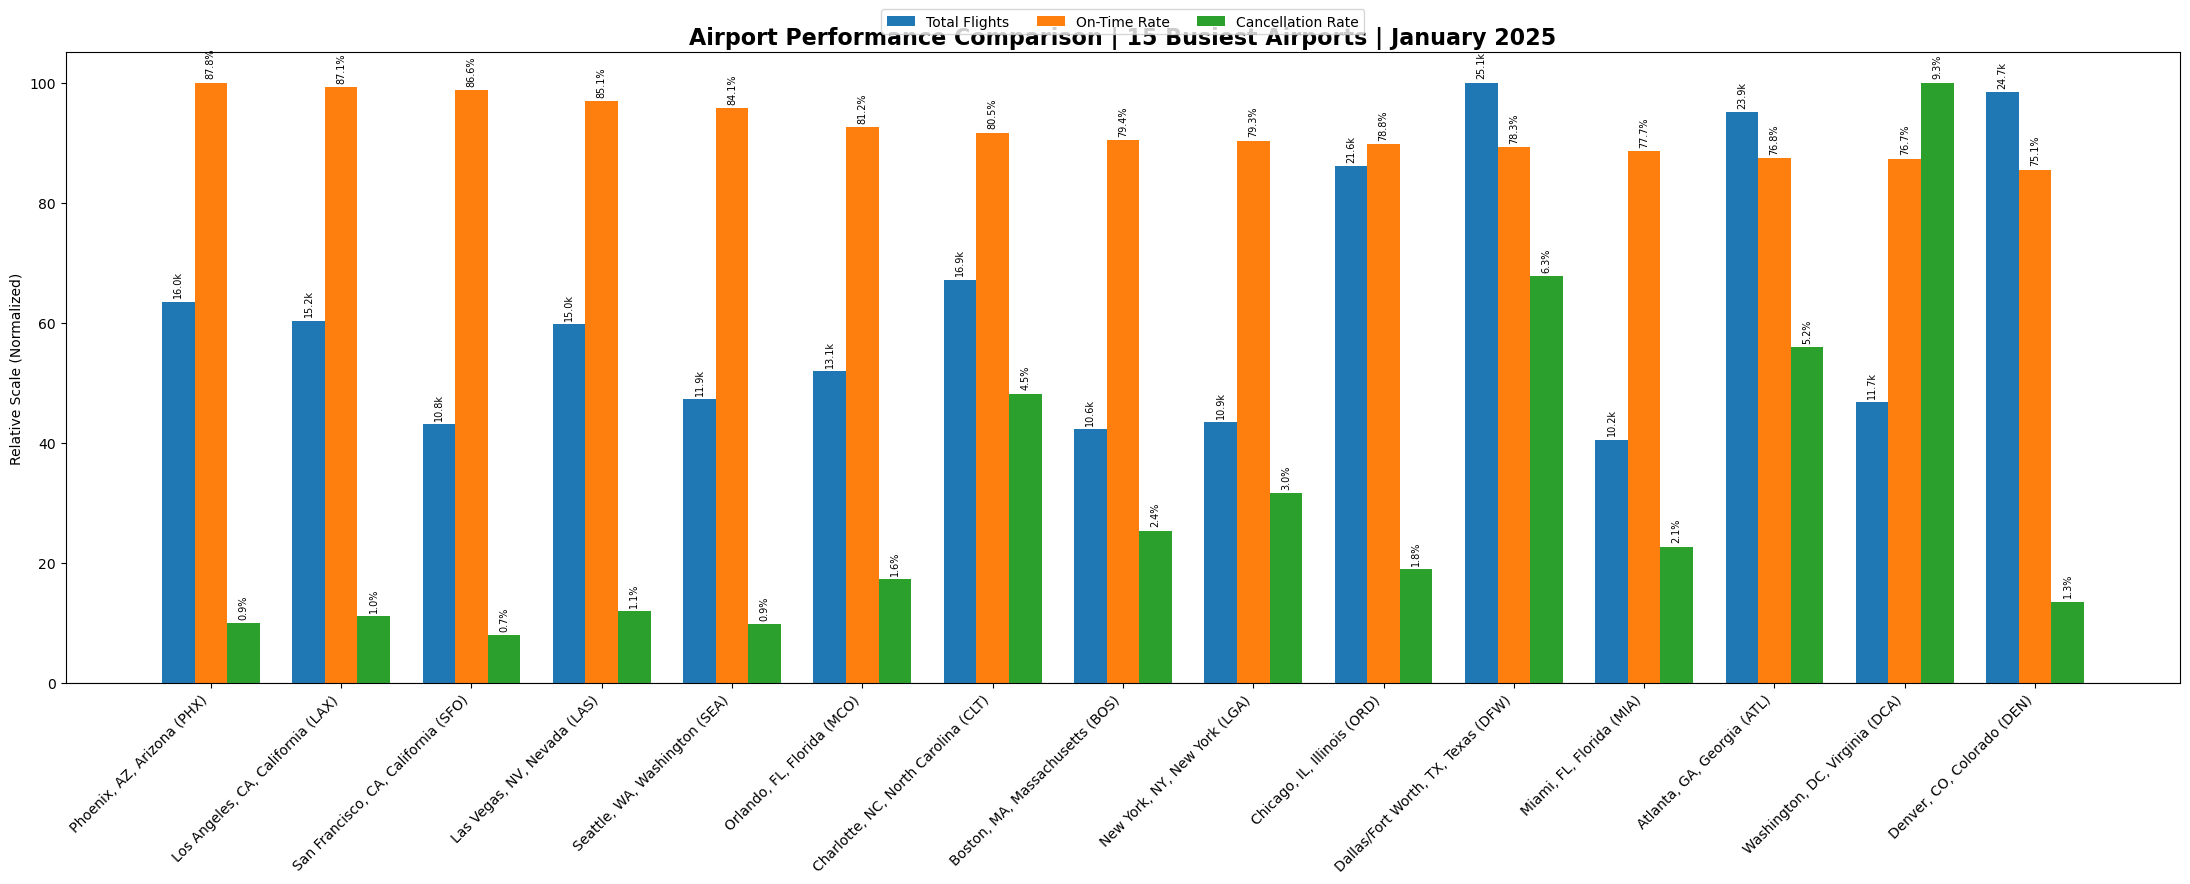

In [8]:
import matplotlib.pyplot as plt
import numpy as np

# Use the 15 busiest airports for a cleaner chart
airport_chart_data = major_airports.sort_values(
    "TotalFlights", ascending=False
).head(15).copy()

# Then sort those airports by on-time rate for display
airport_chart_data = airport_chart_data.sort_values(
    "OnTimeRate", ascending=False
)

# Metrics to compare
metrics = [
    ("TotalFlights", "Total Flights"),
    ("OnTimeRate", "On-Time Rate"),
    ("CancellationRate", "Cancellation Rate")
]

# Normalize values so different scales can be shown together
normalized = {}

for column, label in metrics:
    values = airport_chart_data[column]
    max_abs = values.abs().max()
    normalized[column] = values / max_abs * 100

# Set up grouped bar chart
x = np.arange(len(airport_chart_data))
width = 0.25

fig, ax = plt.subplots(figsize=(22, 9))

for i, (column, label) in enumerate(metrics):
    positions = x + (i - 1) * width

    bars = ax.bar(
        positions,
        normalized[column],
        width,
        label=label
    )

    # Label bars with actual values
    for bar, value in zip(bars, airport_chart_data[column]):
        if column == "TotalFlights":
            text = f"{value / 1000:.1f}k"
        else:
            text = f"{value:.1f}%"

        ax.annotate(
            text,
            (bar.get_x() + bar.get_width() / 2, bar.get_height()),
            xytext=(0, 3),
            textcoords="offset points",
            ha="center",
            va="bottom",
            rotation=90,
            fontsize=7
        )

ax.set_xticks(x)
ax.set_xticklabels(
    airport_chart_data["Airport"],
    rotation=45,
    ha="right"
)

ax.set_ylabel("Relative Scale (Normalized)")
ax.set_title(
    "Airport Performance Comparison | 15 Busiest Airports | January 2025",
    fontsize=16,
    fontweight="bold"
)

ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.08))
ax.axhline(0, color="gray", linewidth=0.8)

plt.tight_layout()
plt.show()

To keep the chart readable, this figure focuses on the 15 busiest airports in the dataset. Bar heights are normalized for visual comparison, and the labels show the actual values.

Initial Findings

On-time arrival rates varied across the 85 airports analyzed. Long Beach ranked highest at 89.89%, while Aspen ranked lowest at 66.49%.

Among larger airports, Phoenix and Los Angeles performed particularly well, with on-time rates above 87%. In comparison, Denver (75.06%), Atlanta (76.76%) and Dallas/Fort Worth (78.32%) had lower on-time rates despite handling some of the highest flight volumes.

Cancellation rates also varied. Savannah recorded the highest rate at 10.69%, while Denver had a relatively low cancellation rate of 1.27% despite its weaker on-time performance.

These findings suggest that airport size alone does not explain differences in reliability. Comparing airline performance at the same airports and on the same routes may help explain these differences.


Airport Network Exposure Analysis

The airport rankings show that on-time performance varies by location. This analysis tests whether some airlines operate more heavily at challenging airports.

For each airline, we calculate the on-time performance of other airlines at the airports it serves, weighted by its completed flights at each airport.

We then compare that result with the overall on-time rate of its competitors to determine whether its airport network appears more or less challenging than average.

In [9]:

import pandas as pd
import numpy as np

# Count completed and on-time flights by airport and airline
airport_airline = flights.groupby(
    ["Origin", "Reporting_Airline"]
).agg(
    Scheduled=("FlightDate", "size"),
    Completed=("Completed", "sum"),
    OnTime=("OnTime", "sum")
).reset_index()

# Get totals for each airport across all airlines
airport_totals = airport_airline.groupby("Origin")[
    ["Completed", "OnTime"]
].sum().rename(columns={
    "Completed": "AirportCompleted",
    "OnTime": "AirportOnTime"
}).reset_index()

# Get totals for each airline across all airports
airline_totals = airport_airline.groupby(
    "Reporting_Airline"
)[["Completed", "OnTime"]].sum().reset_index()

# Exclude each airline's own flights from its airport benchmark
comparison = airport_airline.merge(
    airport_totals, on="Origin"
)

comparison["PeerCompleted"] = (
    comparison["AirportCompleted"] - comparison["Completed"]
)

comparison["PeerOnTime"] = (
    comparison["AirportOnTime"] - comparison["OnTime"]
)

# Require at least 30 competitor flights at each airport
comparison["Eligible"] = (
    (comparison["PeerCompleted"] >= 30) &
    (comparison["Completed"] > 0)
)

comparison["PeerAirportRate"] = np.where(
    comparison["Eligible"],
    comparison["PeerOnTime"] / comparison["PeerCompleted"],
    np.nan
)

# Weight airport benchmark by each airline's completed flights
comparison["WeightedBenchmark"] = (
    comparison["Completed"] * comparison["PeerAirportRate"]
)

eligible = comparison[comparison["Eligible"]].copy()

network_exposure = eligible.groupby(
    "Reporting_Airline"
).agg(
    CoveredFlights=("Completed", "sum"),
    WeightedBenchmark=("WeightedBenchmark", "sum"),
    AirportsCompared=("Origin", "nunique")
).reset_index()

network_exposure = network_exposure.merge(
    airline_totals,
    on="Reporting_Airline"
)

# Weighted average competitor performance at airports served
network_exposure["AirportBenchmark"] = (
    network_exposure["WeightedBenchmark"] /
    network_exposure["CoveredFlights"] * 100
)

# Calculate each airline's national competitor benchmark
all_completed = airline_totals["Completed"].sum()
all_ontime = airline_totals["OnTime"].sum()

network_exposure["NationalPeerRate"] = (
    (all_ontime - network_exposure["OnTime"]) /
    (all_completed - network_exposure["Completed"]) * 100
)

# Negative values suggest a more challenging airport mix
network_exposure["AirportExposureGap"] = (
    network_exposure["AirportBenchmark"] -
    network_exposure["NationalPeerRate"]
)

# Show how much of each airline's activity was evaluated
network_exposure["Coverage"] = (
    network_exposure["CoveredFlights"] /
    network_exposure["Completed"] * 100
)

network_exposure["Airline"] = (
    network_exposure["Reporting_Airline"].map(airline_names)
)

network_exposure = network_exposure.sort_values(
    "AirportExposureGap"
).reset_index(drop=True)

# Present results
display(
    network_exposure[
        [
            "Airline",
            "AirportBenchmark",
            "NationalPeerRate",
            "AirportExposureGap",
            "Coverage",
            "AirportsCompared"
        ]
    ].rename(columns={
        "AirportBenchmark": "Airport-Mix Benchmark (%)",
        "NationalPeerRate": "National Peer Benchmark (%)",
        "AirportExposureGap": "Exposure Gap (pp)",
        "Coverage": "Flight Coverage (%)",
        "AirportsCompared": "Airports"
    }).style.hide(axis="index").format({
        "Airport-Mix Benchmark (%)": "{:.2f}%",
        "National Peer Benchmark (%)": "{:.2f}%",
        "Exposure Gap (pp)": "{:+.2f}",
        "Flight Coverage (%)": "{:.1f}%"
    })
)

# Summarize United's position
united_exposure = network_exposure[
    network_exposure["Reporting_Airline"] == "UA"
].iloc[0]

print("\nUNITED AIRLINES AIRPORT EXPOSURE")
print(
    "Airport-mix benchmark:",
    f'{united_exposure["AirportBenchmark"]:.2f}%'
)
print(
    "National peer benchmark:",
    f'{united_exposure["NationalPeerRate"]:.2f}%'
)
print(
    "Airport exposure gap:",
    f'{united_exposure["AirportExposureGap"]:+.2f} pp'
)
print(
    "Completed-flight coverage:",
    f'{united_exposure["Coverage"]:.1f}%'
)


Airline,Airport-Mix Benchmark (%),National Peer Benchmark (%),Exposure Gap (pp),Flight Coverage (%),Airports
Republic Airways,78.11%,81.06%,-2.95,100.0%,82
Envoy Air,79.42%,81.20%,-1.78,94.9%,132
Allegiant Air,79.73%,81.30%,-1.56,64.1%,97
United Airlines,79.90%,81.06%,-1.16,99.8%,117
Delta Air Lines,80.38%,81.30%,-0.92,100.0%,140
PSA Airlines,80.61%,81.47%,-0.85,99.7%,92
Frontier Airlines,80.81%,81.42%,-0.62,99.5%,79
JetBlue Airways,80.88%,81.41%,-0.53,99.6%,55
American Airlines,80.79%,81.28%,-0.49,100.0%,119
Spirit Airlines,80.86%,81.19%,-0.33,98.7%,58



UNITED AIRLINES AIRPORT EXPOSURE
Airport-mix benchmark: 79.90%
National peer benchmark: 81.06%
Airport exposure gap: -1.16 pp
Completed-flight coverage: 99.8%


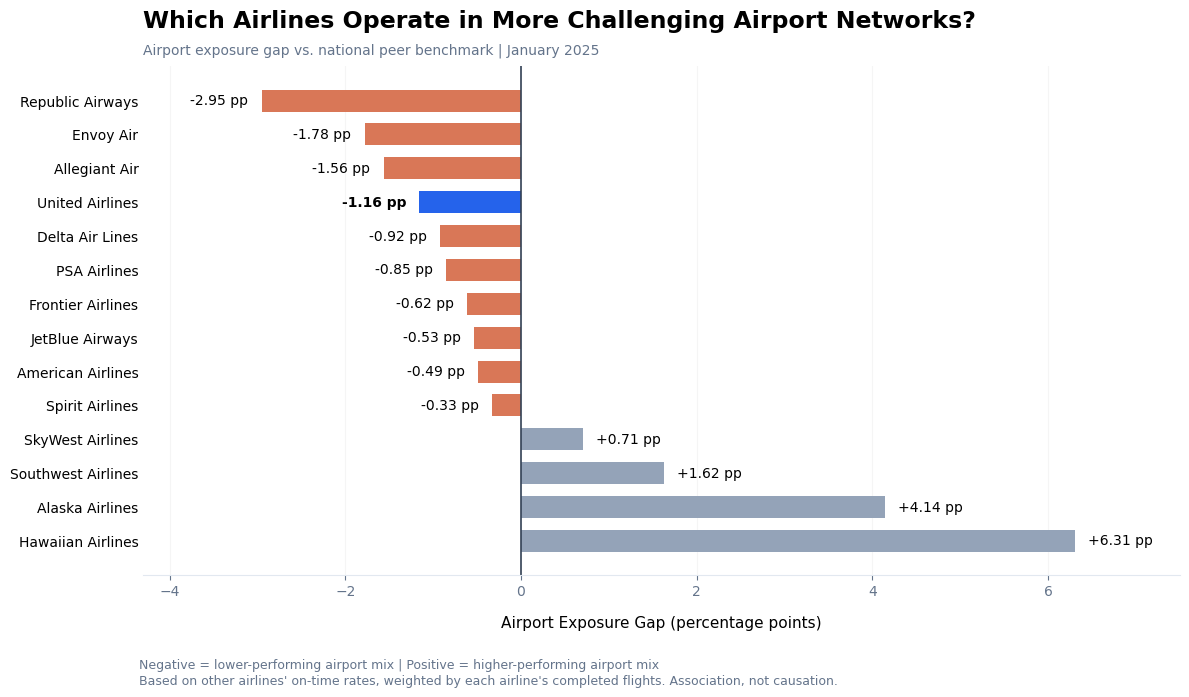

In [10]:

import matplotlib.pyplot as plt
import numpy as np

# Sort airlines from most challenging to least challenging airport mix
plot_data = network_exposure.sort_values(
    "AirportExposureGap",
    ascending=True
).copy()

# Use airline names and calculated exposure gaps
airlines = plot_data["Airline"]
gaps = plot_data["AirportExposureGap"]

# Highlight United
colors = [
    "#2563EB" if code == "UA" else
    "#D97757" if gap < 0 else "#94A3B8"
    for code, gap in zip(
        plot_data["Reporting_Airline"],
        gaps
    )
]

fig, ax = plt.subplots(figsize=(12, 7))

bars = ax.barh(
    airlines,
    gaps,
    color=colors,
    height=0.65
)

# Put most challenging airport network at top
ax.invert_yaxis()

# Reference line at zero
ax.axvline(
    0,
    color="#334155",
    linewidth=1.2
)

# Add exact values beside bars
for bar, gap in zip(bars, gaps):
    y = bar.get_y() + bar.get_height() / 2

    ax.text(
        gap - 0.15 if gap < 0 else gap + 0.15,
        y,
        f"{gap:+.2f} pp",
        va="center",
        ha="right" if gap < 0 else "left",
        fontsize=10,
        fontweight="bold" if bar.get_facecolor() == (37/255, 99/255, 235/255, 1) else "normal"
    )

# Chart title and subtitle
ax.set_title(
    "Which Airlines Operate in More Challenging Airport Networks?",
    fontsize=17,
    fontweight="bold",
    loc="left",
    pad=28
)

ax.text(
    0,
    1.025,
    "Airport exposure gap vs. national peer benchmark | January 2025",
    transform=ax.transAxes,
    fontsize=10,
    color="#64748B"
)

ax.set_xlabel(
    "Airport Exposure Gap (percentage points)",
    fontsize=11,
    labelpad=12
)

# Remove unnecessary borders
for spine in ax.spines.values():
    spine.set_visible(False)

ax.spines["bottom"].set_visible(True)
ax.spines["bottom"].set_color("#E2E8F0")

ax.tick_params(axis="y", length=0, labelsize=10)
ax.tick_params(axis="x", colors="#64748B")

ax.set_xlim(-4.3, 7.5)
ax.grid(axis="x", alpha=0.12)
ax.set_axisbelow(True)

# Explanatory footnote
fig.text(
    0.12,
    0.015,
    "Negative = lower-performing airport mix | Positive = higher-performing airport mix\n"
    "Based on other airlines' on-time rates, weighted by each airline's completed flights. "
    "Association, not causation.",
    fontsize=9,
    color="#64748B"
)

plt.tight_layout(rect=[0, 0.07, 1, 1])
plt.show()


Airport exposure vs on-time rate: Pearson r = +0.44, p = 0.113 (n = 14 airlines)


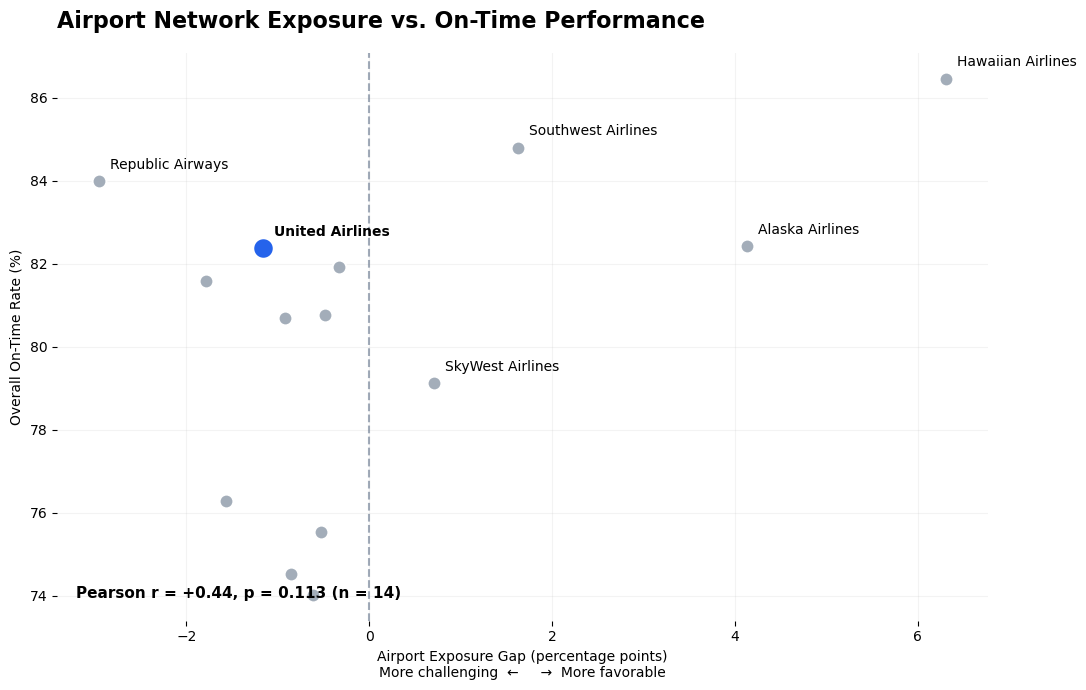

In [11]:

import matplotlib.pyplot as plt
import numpy as np

# Combine airport exposure and overall on-time performance
airport_vs_reliability = network_exposure.merge(
    airline_performance[
        ["Reporting_Airline", "OnTimeRate"]
    ],
    on="Reporting_Airline",
    how="inner"
)

# Calculate correlation
from scipy.stats import pearsonr

correlation = airport_vs_reliability[
    ["AirportExposureGap", "OnTimeRate"]
].corr().iloc[0, 1]
_, airport_p = pearsonr(airport_vs_reliability["AirportExposureGap"], airport_vs_reliability["OnTimeRate"])
assert len(airport_vs_reliability) == 14
print(f"Airport exposure vs on-time rate: Pearson r = {correlation:+.2f}, p = {airport_p:.3f} (n = 14 airlines)")

fig, ax = plt.subplots(figsize=(11, 7))

# Plot all airlines
for _, row in airport_vs_reliability.iterrows():
    is_united = row["Reporting_Airline"] == "UA"

    ax.scatter(
        row["AirportExposureGap"],
        row["OnTimeRate"],
        s=220 if is_united else 100,
        color="#2563EB" if is_united else "#A3ADB9",
        edgecolor="white",
        linewidth=1.5,
        zorder=3
    )

# Label selected airlines for readability
highlight = ["UA", "HA", "OO", "WN", "AS", "YX"]

for _, row in airport_vs_reliability[
    airport_vs_reliability["Reporting_Airline"].isin(highlight)
].iterrows():

    ax.annotate(
        row["Airline"],
        (row["AirportExposureGap"], row["OnTimeRate"]),
        xytext=(8, 9),
        textcoords="offset points",
        fontsize=10,
        fontweight="bold" if row["Reporting_Airline"] == "UA" else "normal"
    )

ax.axvline(0, color="#64748B", linestyle="--", alpha=0.6)

ax.set_title(
    "Airport Network Exposure vs. On-Time Performance",
    fontsize=16,
    fontweight="bold",
    loc="left",
    pad=18
)

ax.set_xlabel(
    "Airport Exposure Gap (percentage points)\n"
    "More challenging  ←     →  More favorable"
)

ax.set_ylabel("Overall On-Time Rate (%)")

ax.text(
    0.02, 0.04,
    f"Pearson r = {correlation:+.2f}, p = {airport_p:.3f} (n = 14)",
    transform=ax.transAxes,
    fontsize=11,
    fontweight="bold"
)

ax.grid(alpha=0.15)
ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.show()


**Airport exposure finding:** Across 14 airlines, more favorable airport exposure was positively associated with higher overall on-time performance (Pearson r = +0.44), but the relationship was **not statistically significant** (p ≈ 0.11), so with only 14 airlines it could be chance. United's airport exposure gap was −1.16 percentage points, suggesting its airport mix is somewhat more challenging than its national peer benchmark. Exposure is measured on **departure (origin) airports only**; conditions at arrival airports are not included. These are associations, not evidence that airports caused an airline's ranking.

### **Analysis 3: Flight Volume & Ranking Confidence**

This section asks two different questions: **Do airlines with fewer flights perform better?** And **does sample size affect how precisely we can estimate each airline's on-time rate?**

FLIGHT VOLUME VS. ON-TIME PERFORMANCE
Airlines analyzed: 14
Pearson correlation: +0.298
Pearson p-value: 0.3004
Spearman correlation: +0.174
Spearman p-value: 0.5528


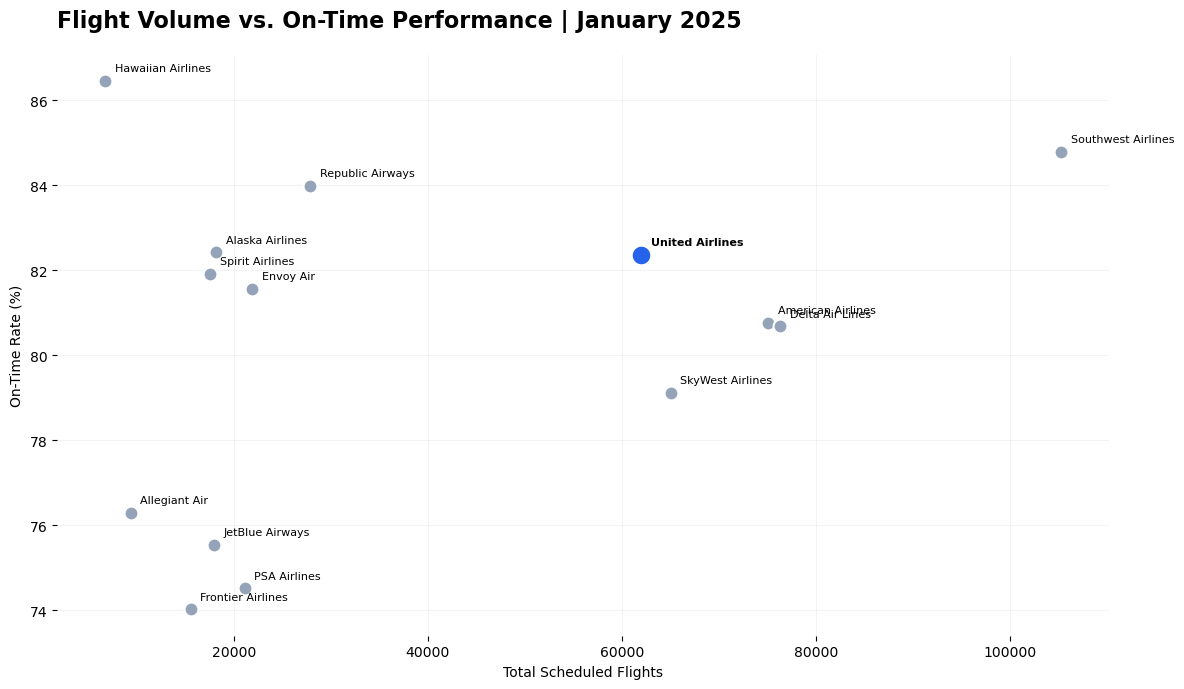

Airline,TotalFlights,OnTimeRate
Southwest Airlines,"105,307",84.79%
Delta Air Lines,"76,306",80.68%
American Airlines,"75,088",80.77%
SkyWest Airlines,"65,036",79.12%
United Airlines,"62,007",82.37%
Republic Airways,"27,833",83.98%
Envoy Air,"21,890",81.57%
PSA Airlines,"21,094",74.52%
Alaska Airlines,"18,163",82.42%
JetBlue Airways,"17,918",75.54%


In [12]:

import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr

# Prepare airline volume and reliability data
volume_analysis = airline_performance[
    [
        "Reporting_Airline",
        "Airline",
        "TotalFlights",
        "OnTimeRate"
    ]
].copy()

# Calculate correlations
pearson_r, pearson_p = pearsonr(
    volume_analysis["TotalFlights"],
    volume_analysis["OnTimeRate"]
)

spearman_r, spearman_p = spearmanr(
    volume_analysis["TotalFlights"],
    volume_analysis["OnTimeRate"]
)

# Display statistical results
print("FLIGHT VOLUME VS. ON-TIME PERFORMANCE")
print(f"Airlines analyzed: {len(volume_analysis)}")
print(f"Pearson correlation: {pearson_r:+.3f}")
print(f"Pearson p-value: {pearson_p:.4f}")
print(f"Spearman correlation: {spearman_r:+.3f}")
print(f"Spearman p-value: {spearman_p:.4f}")

# Create scatter plot
fig, ax = plt.subplots(figsize=(12, 7))

for _, row in volume_analysis.iterrows():

    is_united = row["Reporting_Airline"] == "UA"

    ax.scatter(
        row["TotalFlights"],
        row["OnTimeRate"],
        s=200 if is_united else 100,
        color="#2563EB" if is_united else "#94A3B8",
        edgecolor="white",
        linewidth=1.5,
        zorder=3
    )

    ax.annotate(
        row["Airline"],
        (row["TotalFlights"], row["OnTimeRate"]),
        xytext=(7, 7),
        textcoords="offset points",
        fontsize=8,
        fontweight="bold" if is_united else "normal"
    )

ax.set_title(
    "Flight Volume vs. On-Time Performance | January 2025",
    fontsize=16,
    fontweight="bold",
    loc="left",
    pad=20
)

ax.set_xlabel("Total Scheduled Flights")
ax.set_ylabel("On-Time Rate (%)")

ax.grid(alpha=0.15)
ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.show()

# Display airline data ranked by flight volume
display(
    volume_analysis.sort_values(
        "TotalFlights",
        ascending=False
    )[
        ["Airline", "TotalFlights", "OnTimeRate"]
    ].style.hide(axis="index").format({
        "TotalFlights": "{:,.0f}",
        "OnTimeRate": "{:.2f}%"
    })
)



How Does Flight Volume Affect Ranking Confidence?

Airline on-time rankings are based on percentages, but those percentages come from different numbers of flights.

We calculate 95% confidence intervals for each airline's on-time rate using the Wilson method. These intervals show the uncertainty around each airline's observed performance.

This helps identify airlines with nearly identical on-time rates that may not be meaningfully different, even when their rankings differ.


AIRLINE ON-TIME RANKINGS WITH 95% CONFIDENCE INTERVALS


Rank,Airline,CompletedFlights,OnTimeRate,CI_Lower,CI_Upper
1,Hawaiian Airlines,"6,540",86.45%,85.60%,87.26%
2,Southwest Airlines,"102,120",84.79%,84.57%,85.01%
3,Republic Airways,"26,683",83.98%,83.54%,84.42%
4,Alaska Airlines,"17,847",82.42%,81.86%,82.97%
5,United Airlines,"60,668",82.37%,82.07%,82.67%
6,Spirit Airlines,"16,946",81.92%,81.33%,82.49%
7,Envoy Air,"20,831",81.57%,81.04%,82.09%
8,American Airlines,"72,082",80.77%,80.48%,81.06%
9,Delta Air Lines,"74,025",80.68%,80.39%,80.96%
10,SkyWest Airlines,"63,502",79.12%,78.80%,79.43%


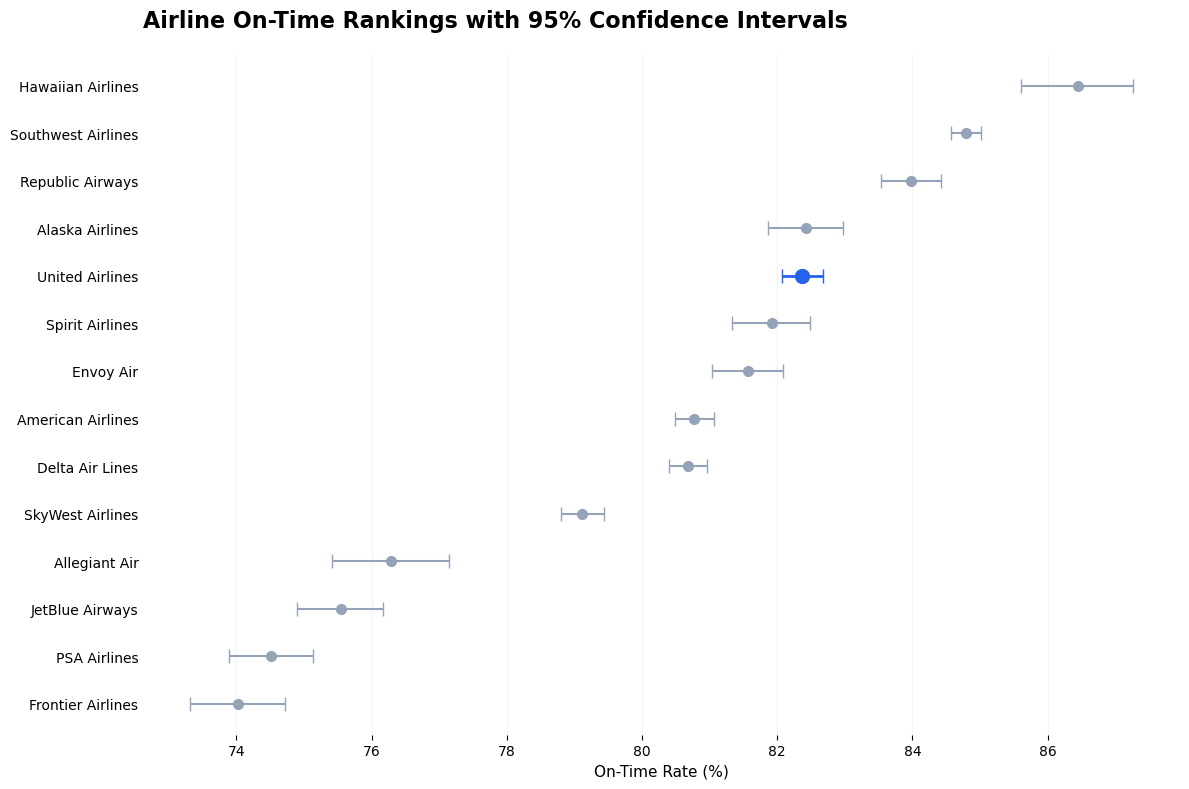


ALASKA VS. UNITED


Airline,CompletedFlights,OnTimeRate,CI_Lower,CI_Upper
Alaska Airlines,"17,847",82.42%,81.86%,82.97%
United Airlines,"60,668",82.37%,82.07%,82.67%


In [13]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.stats.proportion import proportion_confint

# Prepare airline performance data
ranking_confidence = airline_performance[
    [
        "Reporting_Airline",
        "Airline",
        "CompletedFlights",
        "OnTimeFlights",
        "OnTimeRate"
    ]
].copy()

# Calculate 95% Wilson confidence intervals
lower, upper = proportion_confint(
    count=ranking_confidence["OnTimeFlights"],
    nobs=ranking_confidence["CompletedFlights"],
    alpha=0.05,
    method="wilson"
)

ranking_confidence["CI_Lower"] = lower * 100
ranking_confidence["CI_Upper"] = upper * 100

# Rank airlines by on-time performance
ranking_confidence = ranking_confidence.sort_values(
    "OnTimeRate",
    ascending=False
).reset_index(drop=True)

ranking_confidence["Rank"] = ranking_confidence.index + 1

# Display complete results
print("AIRLINE ON-TIME RANKINGS WITH 95% CONFIDENCE INTERVALS")

display(
    ranking_confidence[
        [
            "Rank",
            "Airline",
            "CompletedFlights",
            "OnTimeRate",
            "CI_Lower",
            "CI_Upper"
        ]
    ].style.hide(axis="index").format({
        "CompletedFlights": "{:,.0f}",
        "OnTimeRate": "{:.2f}%",
        "CI_Lower": "{:.2f}%",
        "CI_Upper": "{:.2f}%"
    })
)

# Create confidence interval chart
fig, ax = plt.subplots(figsize=(12, 8))

for _, row in ranking_confidence.iterrows():

    is_united = row["Reporting_Airline"] == "UA"

    # Correct shape for lower and upper error bars
    lower_error = row["OnTimeRate"] - row["CI_Lower"]
    upper_error = row["CI_Upper"] - row["OnTimeRate"]

    ax.errorbar(
        x=row["OnTimeRate"],
        y=row["Airline"],
        xerr=[
            [lower_error],
            [upper_error]
        ],
        fmt="o",
        color="#2563EB" if is_united else "#94A3B8",
        markersize=10 if is_united else 7,
        capsize=5,
        elinewidth=2 if is_united else 1.5,
        linewidth=2 if is_united else 1.5
    )

# Put highest-ranked airline at the top
ax.invert_yaxis()

ax.set_title(
    "Airline On-Time Rankings with 95% Confidence Intervals",
    fontsize=16,
    fontweight="bold",
    loc="left",
    pad=20
)

ax.set_xlabel("On-Time Rate (%)", fontsize=11)

ax.grid(axis="x", alpha=0.15)
ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(axis="y", length=0)

plt.tight_layout()
plt.show()

# Compare Alaska and United specifically
print("\nALASKA VS. UNITED")

alaska_united = ranking_confidence[
    ranking_confidence["Reporting_Airline"].isin(["AS", "UA"])
].copy()

display(
    alaska_united[
        [
            "Airline",
            "CompletedFlights",
            "OnTimeRate",
            "CI_Lower",
            "CI_Upper"
        ]
    ].style.hide(axis="index").format({
        "CompletedFlights": "{:,.0f}",
        "OnTimeRate": "{:.2f}%",
        "CI_Lower": "{:.2f}%",
        "CI_Upper": "{:.2f}%"
    })
)


### **Analysis 4: Shared-Route Reliability Comparisons**

The earlier sections establish overall rankings, airport exposure and flight volume. This section compares each airline's on-time performance with competitors on qualifying shared routes; it uses a different ranking measure and a narrower sample than the overall rankings.

 Comparing Airlines on the Same Routes

Compared airlines operating on the same routes to see whether differences in route networks help explain airline reliability rankings. This will help identify which airlines perform better or worse than their direct competitors.


In [14]:

# Count the number of airlines operating on each route
route_competition = flights.groupby("Route").agg(
    Airlines=("Reporting_Airline", "nunique"),
    TotalFlights=("FlightDate", "count")
).reset_index()

# Keep routes served by at least two airlines
shared_routes = route_competition[
    route_competition["Airlines"] >= 2
].copy()

# Check how many routes qualify
print("Total routes:", len(route_competition))
print("Routes served by at least two airlines:", len(shared_routes))

# Check how many flights operate on shared routes
shared_flights = flights[
    flights["Route"].isin(shared_routes["Route"])
].copy()

print("Flights on shared routes:", len(shared_flights))
print(
    "Percentage of all flights on shared routes:",
    round(len(shared_flights) / len(flights) * 100, 2),
    "%"
)


Total routes: 5649
Routes served by at least two airlines: 2220


Flights on shared routes: 386054
Percentage of all flights on shared routes: 71.52 %



Selecting Routes for Comparison

Of the 5,649 routes in the dataset, 2,220 were served by at least two airlines, representing 71.52% of all flights.

To make comparisons more reliable, each airline must have at least 20 flights on a route, and each route must have at least two airlines meeting that requirement.


In [15]:

# Count scheduled flights by airline and route
route_airline_counts = shared_flights.groupby(
    ["Route", "Reporting_Airline"]
).size().reset_index(name="FlightCount")

# Keep airlines with at least 20 flights per route
qualified_airlines = route_airline_counts[
    route_airline_counts["FlightCount"] >= 20
].copy()

# Identify routes with at least two qualifying airlines
qualified_routes = qualified_airlines.groupby("Route").filter(
    lambda x: x["Reporting_Airline"].nunique() >= 2
)

# Keep flights that meet both requirements
qualified_flights = shared_flights.merge(
    qualified_routes[["Route", "Reporting_Airline"]],
    on=["Route", "Reporting_Airline"],
    how="inner"
)

# Summarize the comparison sample
print("Routes qualifying for comparison:",
      qualified_flights["Route"].nunique())

print("Airlines included:",
      qualified_flights["Reporting_Airline"].nunique())

print("Flights included:",
      len(qualified_flights))

print("Percentage of all flights:",
      round(len(qualified_flights) / len(flights) * 100, 2), "%")


Routes qualifying for comparison: 1636
Airlines included: 14
Flights included: 335595
Percentage of all flights: 62.18 %


Route-Adjusted Airline Comparison

Compared each airline's on-time arrival rate with competitors operating on the same routes. Results are weighted by completed flight counts to show whether airlines generally perform better or worse than their direct competitors.


In [16]:

# Calculate on-time performance for each airline on each route
route_results = qualified_flights.groupby(
    ["Route", "Reporting_Airline"]
).agg(
    CompletedFlights=("Completed", "sum"),
    OnTimeFlights=("OnTime", "sum")
).reset_index()

# Calculate total performance across all airlines on each route
route_totals = route_results.groupby("Route").agg(
    RouteCompleted=("CompletedFlights", "sum"),
    RouteOnTime=("OnTimeFlights", "sum")
).reset_index()

route_results = route_results.merge(route_totals, on="Route")

# Calculate performance of competing airlines, excluding the airline being evaluated
route_results["CompetitorFlights"] = (
    route_results["RouteCompleted"] - route_results["CompletedFlights"]
)

route_results["CompetitorOnTime"] = (
    route_results["RouteOnTime"] - route_results["OnTimeFlights"]
)

route_results["CompetitorRate"] = (
    route_results["CompetitorOnTime"] /
    route_results["CompetitorFlights"]
)

# Calculate each airline's performance and expected performance
route_results["ExpectedOnTime"] = (
    route_results["CompletedFlights"] * route_results["CompetitorRate"]
)

adjusted_performance = route_results.groupby(
    "Reporting_Airline"
).agg(
    CompletedFlights=("CompletedFlights", "sum"),
    OnTimeFlights=("OnTimeFlights", "sum"),
    ExpectedOnTime=("ExpectedOnTime", "sum")
).reset_index()

# Compare actual performance with route competitors
adjusted_performance["ActualRate"] = (
    adjusted_performance["OnTimeFlights"] /
    adjusted_performance["CompletedFlights"] * 100
)

adjusted_performance["CompetitorBenchmark"] = (
    adjusted_performance["ExpectedOnTime"] /
    adjusted_performance["CompletedFlights"] * 100
)

adjusted_performance["PerformanceGap"] = (
    adjusted_performance["ActualRate"] -
    adjusted_performance["CompetitorBenchmark"]
)

# Add full airline names
adjusted_performance["Airline"] = (
    adjusted_performance["Reporting_Airline"].map(airline_names)
)

# Rank airlines by performance relative to route competitors
adjusted_performance = adjusted_performance.sort_values(
    "PerformanceGap", ascending=False
).reset_index(drop=True)

adjusted_performance.insert(
    0, "Adjusted Rank", range(1, len(adjusted_performance) + 1)
)

# Create a readable results table
adjusted_summary = adjusted_performance[
    [
        "Adjusted Rank",
        "Airline",
        "CompletedFlights",
        "ActualRate",
        "CompetitorBenchmark",
        "PerformanceGap"
    ]
].copy()

adjusted_summary.columns = [
    "Adjusted Rank",
    "Airline",
    "Completed Flights",
    "On-Time Rate (%)",
    "Competitor On-Time Rate (%)",
    "Performance Gap (pp)"
]

display(
    adjusted_summary.style.hide(axis="index").format({
        "Completed Flights": "{:,.0f}",
        "On-Time Rate (%)": "{:.2f}%",
        "Competitor On-Time Rate (%)": "{:.2f}%",
        "Performance Gap (pp)": "{:+.2f}"
    })
)


Adjusted Rank,Airline,Completed Flights,On-Time Rate (%),Competitor On-Time Rate (%),Performance Gap (pp)
1,Republic Airways,"17,213",84.17%,78.16%,+6.01
2,Envoy Air,"11,648",81.11%,77.46%,+3.65
3,United Airlines,"47,121",82.62%,79.09%,+3.53
4,Spirit Airlines,"15,049",82.04%,80.10%,+1.94
5,Southwest Airlines,"52,550",84.12%,82.28%,+1.85
6,American Airlines,"49,322",80.94%,80.19%,+0.75
7,Delta Air Lines,"52,484",79.68%,80.55%,-0.87
8,Alaska Airlines,"12,392",82.66%,85.07%,-2.41
9,SkyWest Airlines,"26,750",81.02%,83.54%,-2.52
10,JetBlue Airways,"13,946",75.56%,79.84%,-4.28


In [17]:

# Add readable airport locations
origin_locations = (
    df.drop_duplicates("Origin")
    .set_index("Origin")["OriginCityName"]
    .to_dict()
)

dest_locations = (
    df.drop_duplicates("Dest")
    .set_index("Dest")["DestCityName"]
    .to_dict()
)

# Summarize each qualifying route
route_summary = qualified_flights.groupby(
    ["Route", "Origin", "Dest"]
).agg(
    TotalFlights=("FlightDate", "count"),
    Airlines=("Reporting_Airline", "nunique"),
    CompletedFlights=("Completed", "sum"),
    OnTimeFlights=("OnTime", "sum")
).reset_index()

# Add full city names
route_summary["Route Name"] = (
    route_summary["Origin"].map(origin_locations)
    + " → " +
    route_summary["Dest"].map(dest_locations)
    + " (" + route_summary["Route"] + ")"
)

# Calculate on-time arrival rate
route_summary["OnTimeRate"] = (
    route_summary["OnTimeFlights"] /
    route_summary["CompletedFlights"] * 100
)

# Select the 15 busiest qualifying routes
top_routes = route_summary.nlargest(
    15, "TotalFlights"
).copy()

# Add the names of airlines serving each route
route_airlines = qualified_flights.groupby("Route")[
    "Reporting_Airline"
].unique()

top_routes["Competing Airlines"] = (
    top_routes["Route"].map(
        lambda r: ", ".join(
            sorted(airline_names.get(a, a)
                   for a in route_airlines[r])
        )
    )
)

# Display a readable table
route_display = top_routes[
    [
        "Route Name",
        "TotalFlights",
        "Airlines",
        "OnTimeRate",
        "Competing Airlines"
    ]
].copy()

route_display.columns = [
    "Route",
    "Total Flights",
    "Number of Airlines",
    "On-Time Rate (%)",
    "Competing Airlines"
]

display(
    route_display.style.hide(axis="index").format({
        "Total Flights": "{:,.0f}",
        "On-Time Rate (%)": "{:.2f}%"
    })
)


Route,Total Flights,Number of Airlines,On-Time Rate (%),Competing Airlines
"Kahului, HI → Honolulu, HI (OGG-HNL)",986,2,89.84%,"Hawaiian Airlines, Southwest Airlines"
"Honolulu, HI → Kahului, HI (HNL-OGG)",985,2,92.63%,"Hawaiian Airlines, Southwest Airlines"
"Chicago, IL → New York, NY (ORD-LGA)",923,6,77.90%,"American Airlines, Delta Air Lines, Republic Airways, SkyWest Airlines, Spirit Airlines, United Airlines"
"New York, NY → Chicago, IL (LGA-ORD)",919,6,83.70%,"American Airlines, Delta Air Lines, Republic Airways, SkyWest Airlines, Spirit Airlines, United Airlines"
"Los Angeles, CA → San Francisco, CA (LAX-SFO)",852,7,84.49%,"Alaska Airlines, American Airlines, Delta Air Lines, Frontier Airlines, SkyWest Airlines, Southwest Airlines, United Airlines"
"San Francisco, CA → Los Angeles, CA (SFO-LAX)",849,7,87.01%,"Alaska Airlines, American Airlines, Delta Air Lines, Frontier Airlines, SkyWest Airlines, Southwest Airlines, United Airlines"
"Phoenix, AZ → Denver, CO (PHX-DEN)",793,4,83.16%,"American Airlines, Frontier Airlines, Southwest Airlines, United Airlines"
"Denver, CO → Phoenix, AZ (DEN-PHX)",787,4,80.76%,"American Airlines, Frontier Airlines, Southwest Airlines, United Airlines"
"Boston, MA → Washington, DC (BOS-DCA)",776,4,83.64%,"American Airlines, Envoy Air, JetBlue Airways, Republic Airways"
"Los Angeles, CA → New York, NY (LAX-JFK)",775,3,88.92%,"American Airlines, Delta Air Lines, JetBlue Airways"


In [18]:

# Calculate qualifying route coverage by airline
airline_sample = qualified_flights.groupby(
    "Reporting_Airline"
).agg(
    Routes=("Route", "nunique"),
    SampleFlights=("FlightDate", "count")
).reset_index()

# Calculate total scheduled flights by airline
total_flights = flights.groupby(
    "Reporting_Airline"
).size().reset_index(name="TotalFlights")

airline_sample = airline_sample.merge(
    total_flights,
    on="Reporting_Airline",
    how="left"
)

# Calculate percentage of each airline's flights in sample
airline_sample["SampleCoverage"] = (
    airline_sample["SampleFlights"] /
    airline_sample["TotalFlights"] * 100
)

# Add airline names
airline_sample["Airline"] = (
    airline_sample["Reporting_Airline"].map(airline_names)
)



Route Sample Overview

Reviewed the routes included in our comparison, including flight volume, competing airlines and how much data each airline contributes. This provides context for interpreting the route-adjusted rankings.


In [19]:

# Count flights for each airline on each qualifying route
airline_routes = qualified_flights.groupby(
    ["Reporting_Airline", "Route"]
).size().reset_index(name="RouteFlights")

# Find each airline's busiest qualifying shared route
busiest_routes = (
    airline_routes.sort_values(
        ["Reporting_Airline", "RouteFlights"],
        ascending=[True, False]
    )
    .drop_duplicates("Reporting_Airline")
)

# Add readable route names
busiest_routes["Busiest Shared Route"] = (
    busiest_routes["Route"].apply(
        lambda r: (
            origin_locations.get(r.split("-")[0], r.split("-")[0])
            + " → " +
            dest_locations.get(r.split("-")[1], r.split("-")[1])
            + f" ({r})"
        )
    )
)

# Combine route information with airline sample coverage
competition_summary = airline_sample.merge(
    busiest_routes[
        ["Reporting_Airline", "Busiest Shared Route"]
    ],
    on="Reporting_Airline",
    how="left"
)

# Rank airlines by number of overlapping routes
competition_summary = competition_summary.sort_values(
    "Routes", ascending=False
).reset_index(drop=True)

competition_summary.insert(
    0, "Overlap Rank",
    range(1, len(competition_summary) + 1)
)

# Select and rename columns
competition_display = competition_summary[
    [
        "Overlap Rank",
        "Airline",
        "Routes",
        "SampleFlights",
        "SampleCoverage",
        "Busiest Shared Route"
    ]
].copy()

competition_display.columns = [
    "Overlap Rank",
    "Airline",
    "Overlapping Routes",
    "Flights on Shared Routes",
    "Sample Coverage (%)",
    "Busiest Shared Route"
]

display(
    competition_display.style.hide(axis="index").format({
        "Flights on Shared Routes": "{:,.0f}",
        "Sample Coverage (%)": "{:.2f}%"
    })
)


Overlap Rank,Airline,Overlapping Routes,Flights on Shared Routes,Sample Coverage (%),Busiest Shared Route
1,Southwest Airlines,623,"53,813",51.10%,"Honolulu, HI → Kahului, HI (HNL-OGG)"
2,Delta Air Lines,508,"53,924",70.67%,"Atlanta, GA → Orlando, FL (ATL-MCO)"
3,American Airlines,494,"51,156",68.13%,"Dallas/Fort Worth, TX → Los Angeles, CA (DFW-LAX)"
4,United Airlines,477,"48,047",77.49%,"Newark, NJ → Orlando, FL (EWR-MCO)"
5,SkyWest Airlines,384,"27,166",41.77%,"Colorado Springs, CO → Denver, CO (COS-DEN)"
6,Spirit Airlines,328,"15,574",88.77%,"Fort Lauderdale, FL → Newark, NJ (FLL-EWR)"
7,Frontier Airlines,296,"11,974",77.12%,"Orlando, FL → Philadelphia, PA (MCO-PHL)"
8,Republic Airways,253,"17,953",64.50%,"Boston, MA → Washington, DC (BOS-DCA)"
9,Envoy Air,242,"12,198",55.72%,"Fayetteville, AR → Dallas/Fort Worth, TX (XNA-DFW)"
10,JetBlue Airways,174,"14,233",79.43%,"Boston, MA → Washington, DC (BOS-DCA)"


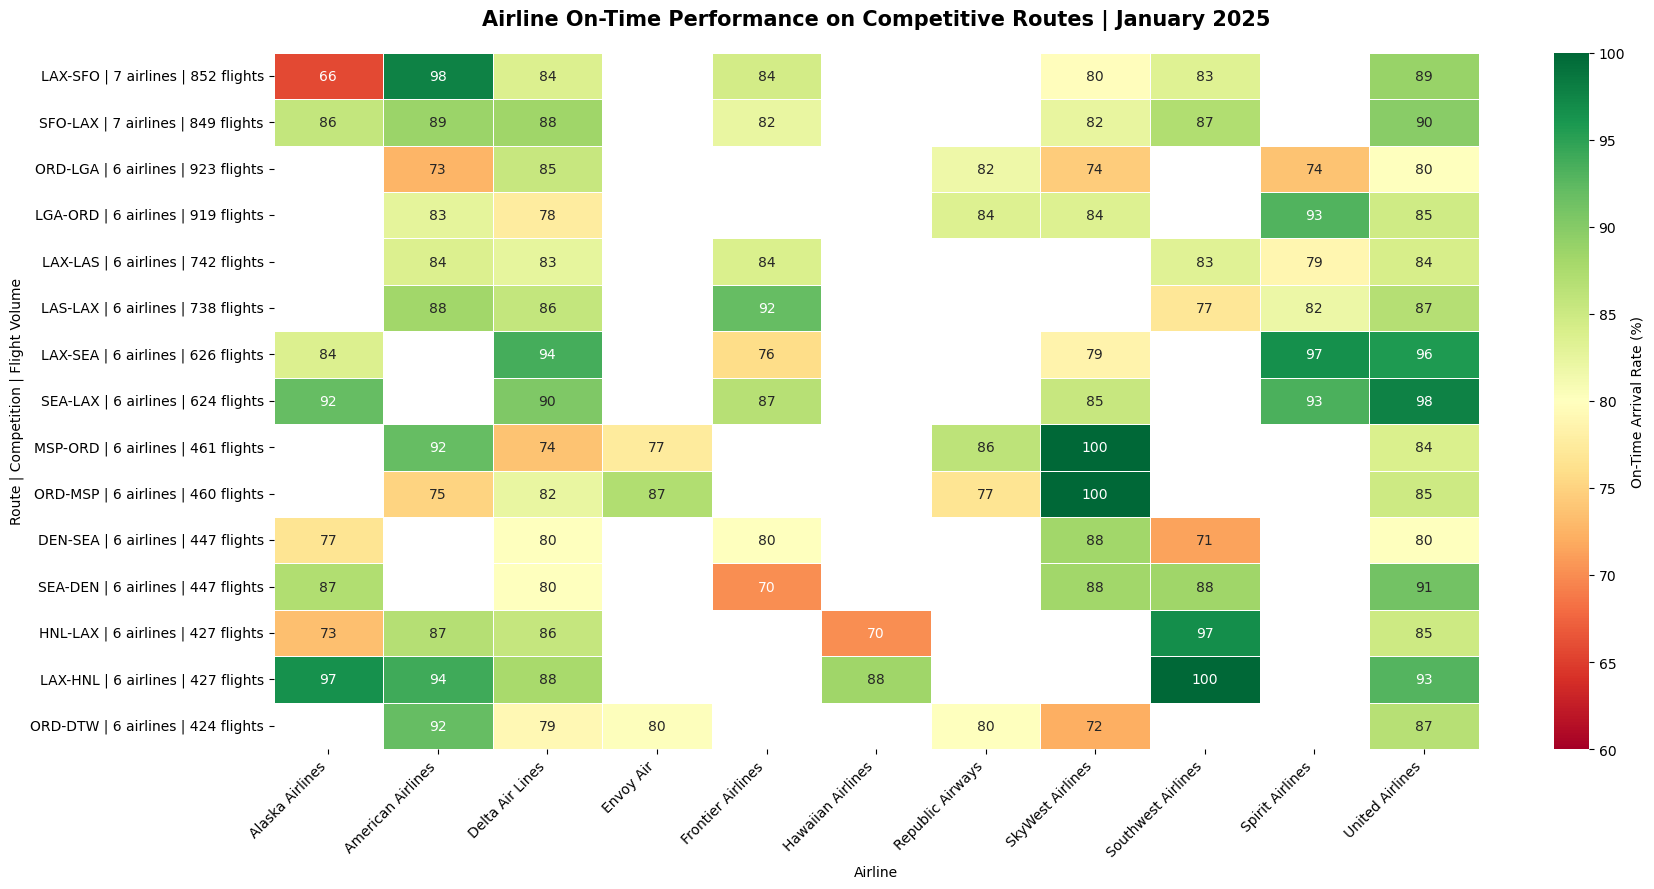

In [20]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Select 15 routes with the most competing airlines
# Use flight volume to break ties
selected_routes = (
    route_summary.sort_values(
        ["Airlines", "TotalFlights"],
        ascending=[False, False]
    )
    .head(15)
    .copy()
)

# Calculate on-time rates by airline and route
route_airline_performance = qualified_flights.groupby(
    ["Route", "Reporting_Airline"]
).agg(
    CompletedFlights=("Completed", "sum"),
    OnTimeFlights=("OnTime", "sum")
).reset_index()

route_airline_performance["OnTimeRate"] = (
    route_airline_performance["OnTimeFlights"] /
    route_airline_performance["CompletedFlights"] * 100
)

# Add airline names
route_airline_performance["Airline"] = (
    route_airline_performance["Reporting_Airline"]
    .map(airline_names)
)

# Keep selected routes
heatmap_data = route_airline_performance[
    route_airline_performance["Route"].isin(
        selected_routes["Route"]
    )
].copy()

# Create route-by-airline table
heatmap_table = heatmap_data.pivot(
    index="Route",
    columns="Airline",
    values="OnTimeRate"
)

# Match route order to our selection
heatmap_table = heatmap_table.reindex(
    selected_routes["Route"]
)

# Add flight counts and airline counts to route labels
route_labels = [
    f"{row.Route} | {row.Airlines} airlines | {row.TotalFlights:,} flights"
    for row in selected_routes.itertuples()
]

heatmap_table.index = route_labels

# Plot heatmap
plt.figure(figsize=(18, 9))

sns.heatmap(
    heatmap_table,
    annot=True,
    fmt=".0f",
    cmap="RdYlGn",
    vmin=60,
    vmax=100,
    mask=heatmap_table.isna(),
    linewidths=0.5,
    cbar_kws={"label": "On-Time Arrival Rate (%)"}
)

plt.title(
    "Airline On-Time Performance on Competitive Routes | January 2025",
    fontsize=15,
    fontweight="bold",
    pad=20
)

plt.xlabel("Airline")
plt.ylabel("Route | Competition | Flight Volume")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


Route-Level Findings

Airline performance varied considerably on the same routes. For example, American Airlines had a 98% on-time arrival rate from Los Angeles to San Francisco, compared with 66% for Alaska Airlines, a 32-percentage-point difference.

United performed well across several competitive routes, including Seattle to Los Angeles (98%) and Los Angeles to Seattle (96%), supporting its stronger position in the route-adjusted rankings.

Performance also differed by direction. Flights from Chicago to New York had a 77.90% on-time rate, compared with 83.70% for flights in the opposite direction.



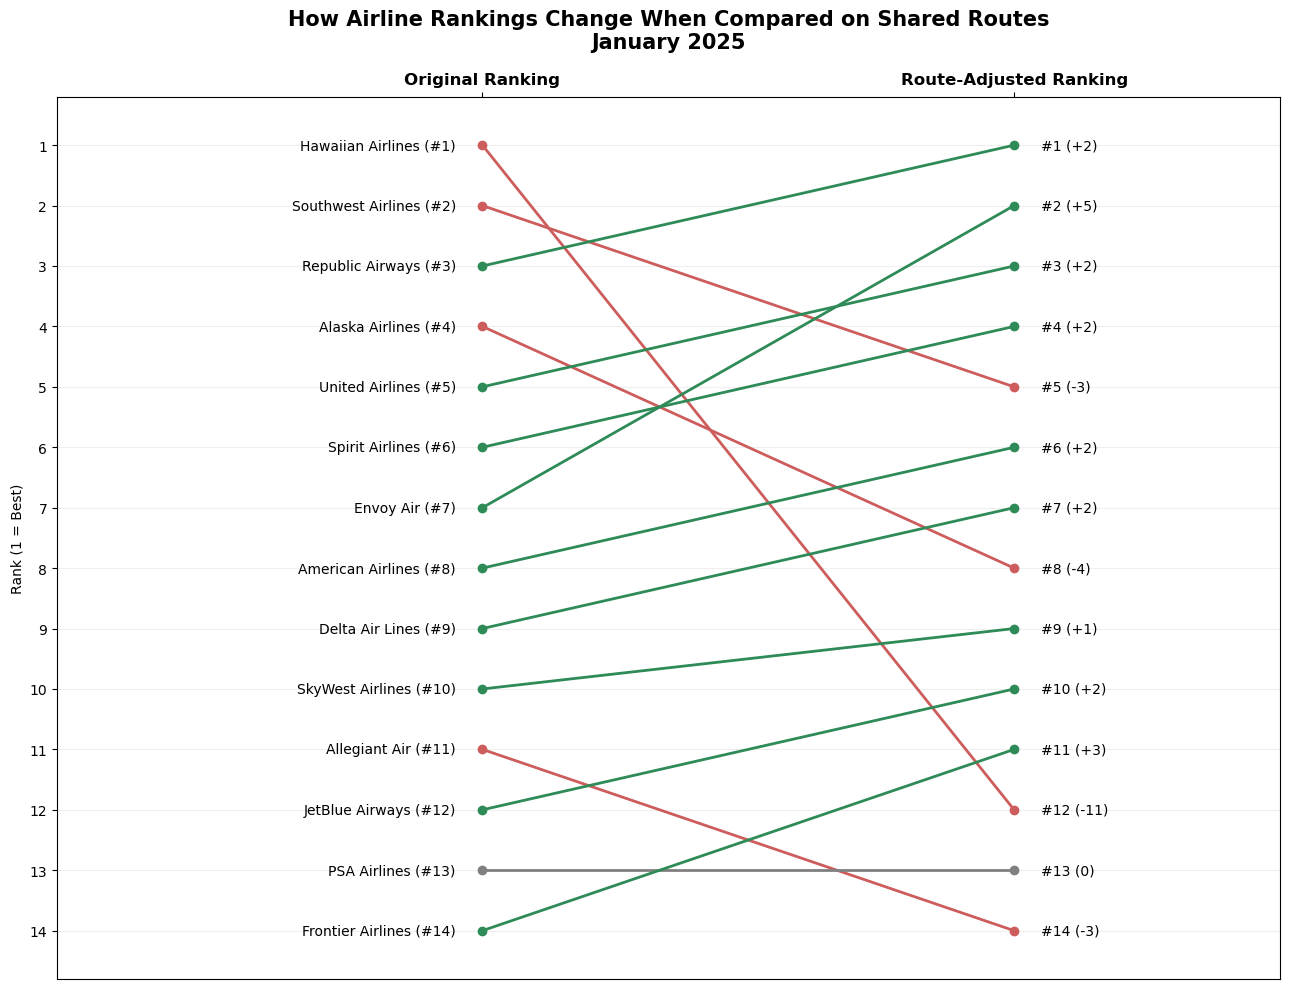

In [21]:

import matplotlib.pyplot as plt

# Create original rankings
original = airline_performance[
    ["Reporting_Airline", "Airline", "OnTimeRate"]
].copy()

original = original.sort_values(
    "OnTimeRate", ascending=False
).reset_index(drop=True)

original["Original Rank"] = range(1, len(original) + 1)

# Create route-adjusted rankings
adjusted = adjusted_performance[
    ["Reporting_Airline", "Adjusted Rank", "PerformanceGap"]
].copy()

# Combine both sets of rankings
ranking_comparison = original.merge(
    adjusted, on="Reporting_Airline"
)

# Calculate changes in ranking
ranking_comparison["Rank Change"] = (
    ranking_comparison["Original Rank"] -
    ranking_comparison["Adjusted Rank"]
)

# Sort by original rank
ranking_comparison = ranking_comparison.sort_values("Original Rank")

# Create before-and-after chart
fig, ax = plt.subplots(figsize=(13, 10))

for _, row in ranking_comparison.iterrows():
    old_rank = row["Original Rank"]
    new_rank = row["Adjusted Rank"]

    if new_rank < old_rank:
        color = "seagreen"
    elif new_rank > old_rank:
        color = "indianred"
    else:
        color = "gray"

    # Connect original and adjusted rankings
    ax.plot(
        [0, 1],
        [old_rank, new_rank],
        marker="o",
        linewidth=2,
        color=color
    )

    # Original airline name and rank
    ax.text(
        -0.05, old_rank,
        f'{row["Airline"]} (#{old_rank})',
        ha="right", va="center",
        fontsize=10
    )

    # Adjusted rank and change
    change = int(row["Rank Change"])
    change_text = f"+{change}" if change > 0 else str(change)

    ax.text(
        1.05, new_rank,
        f'#{new_rank} ({change_text})',
        ha="left", va="center",
        fontsize=10
    )

# Format chart
ax.set_xlim(-0.8, 1.5)
ax.set_ylim(14.8, 0.2)

ax.set_xticks([0, 1])
ax.set_xticklabels(
    ["Original Ranking", "Route-Adjusted Ranking"],
    fontsize=12,
    fontweight="bold"
)

ax.xaxis.tick_top()
ax.set_yticks(range(1, 15))
ax.set_ylabel("Rank (1 = Best)")
ax.grid(axis="y", alpha=0.2)

ax.set_title(
    "How Airline Rankings Change When Compared on Shared Routes\n"
    "January 2025",
    fontsize=15,
    fontweight="bold",
    pad=35
)

plt.tight_layout()
plt.show()


**Route-level monitoring example (supporting analysis)**

The following calculations identify United routes with below-peer on-time rates. These are *candidates for future monitoring*, not proven operational problems or a recommendation to change the network. The two strongest examples feed the monthly executive report; detailed statistics stay in the notebook for auditability.

In [22]:

# Select United Airlines routes
united_routes = route_results[
    route_results["Reporting_Airline"] == "UA"
].copy()

# Calculate United's on-time arrival rate on each route
united_routes["UnitedRate"] = (
    united_routes["OnTimeFlights"] /
    united_routes["CompletedFlights"] * 100
)

# Convert competitor rates to percentages
united_routes["CompetitorRatePct"] = (
    united_routes["CompetitorRate"] * 100
)

# Calculate performance gap in percentage points
united_routes["PerformanceGap"] = (
    united_routes["UnitedRate"] -
    united_routes["CompetitorRatePct"]
)

# Estimate additional on-time arrivals if United matched competitors
united_routes["Opportunity"] = (
    united_routes["CompletedFlights"] *
    (united_routes["CompetitorRatePct"] - united_routes["UnitedRate"]) / 100
).clip(lower=0)

# Focus on routes where United trails competitors
underperforming_routes = united_routes[
    (united_routes["PerformanceGap"] < 0) &
    (united_routes["CompletedFlights"] >= 30)
].copy()

# Rank by potential additional on-time flights
underperforming_routes = underperforming_routes.sort_values(
    "Opportunity", ascending=False
)

# Add readable route names
underperforming_routes["Route Name"] = (
    underperforming_routes["Route"].apply(
        lambda r: (
            origin_locations.get(r.split("-")[0], r.split("-")[0])
            + " → " +
            dest_locations.get(r.split("-")[1], r.split("-")[1])
            + f" ({r})"
        )
    )
)

# Retain the top five for statistical testing; report the top two only.
top_united_opportunities = underperforming_routes.head(5)

united_display = top_united_opportunities.head(2)[
    [
        "Route Name",
        "CompletedFlights",
        "UnitedRate",
        "CompetitorRatePct",
        "PerformanceGap",
        "Opportunity"
    ]
].copy()

united_display.columns = [
    "Route",
    "United Flights",
    "United On-Time Rate (%)",
    "Competitor Rate (%)",
    "Performance Gap (pp)",
    "Potential Additional On-Time Flights"
]

display(
    united_display.style.hide(axis="index").format({
        "United Flights": "{:,.0f}",
        "United On-Time Rate (%)": "{:.2f}%",
        "Competitor Rate (%)": "{:.2f}%",
        "Performance Gap (pp)": "{:+.2f}",
        "Potential Additional On-Time Flights": "{:.1f}"
    })
)


Route,United Flights,United On-Time Rate (%),Competitor Rate (%),Performance Gap (pp),Potential Additional On-Time Flights
"Denver, CO → Chicago, IL (DEN-ORD)",258,68.99%,80.10%,-11.11,28.7
"Newark, NJ → Los Angeles, CA (EWR-LAX)",248,78.23%,89.01%,-10.79,26.7


*Route-relative rankings reflect performance against competitors on qualifying shared routes. Sample coverage varies by airline, and rankings should be interpreted accordingly.*

**Route-level significance checks (supporting analysis)**

Test priority-route gaps across all eligible United routes, adjusting p-values for multiple comparisons. Show the two monitored routes in the summary. These tests help prevent overconfident operational recommendations from one month of data.

In [23]:

import pandas as pd
from statsmodels.stats.proportion import (
    proportions_ztest,
    confint_proportions_2indep
)
from statsmodels.stats.multitest import multipletests

# Select United routes with at least 30 completed flights
# and valid competitor comparisons
test_routes = route_results[
    (route_results["Reporting_Airline"] == "UA") &
    (route_results["CompletedFlights"] >= 30) &
    (route_results["CompetitorFlights"] > 0)
].copy()

# Test United against competitors on each eligible route
results = []

for _, row in test_routes.iterrows():

    united_on_time = int(row["OnTimeFlights"])
    united_total = int(row["CompletedFlights"])

    competitor_on_time = int(row["CompetitorOnTime"])
    competitor_total = int(row["CompetitorFlights"])

    # Two-proportion z-test
    _, p_value = proportions_ztest(
        [united_on_time, competitor_on_time],
        [united_total, competitor_total]
    )

    # 95% confidence interval for the performance gap
    ci_low, ci_high = confint_proportions_2indep(
        united_on_time,
        united_total,
        competitor_on_time,
        competitor_total,
        compare="diff",
        method="newcomb",
        alpha=0.05
    )

    united_rate = united_on_time / united_total
    competitor_rate = competitor_on_time / competitor_total
    gap = (united_rate - competitor_rate) * 100

    # Additional on-time flights if United matched competitors
    opportunity = max(
        0,
        united_total * (competitor_rate - united_rate)
    )

    results.append({
        "Route": row["Route"],
        "United Flights": united_total,
        "Competitor Flights": competitor_total,
        "United On-Time (%)": united_rate * 100,
        "Competitor On-Time (%)": competitor_rate * 100,
        "Gap (pp)": gap,
        "CI Lower (pp)": ci_low * 100,
        "CI Upper (pp)": ci_high * 100,
        "P-Value": p_value,
        "Potential Additional Flights": opportunity
    })

stat_results = pd.DataFrame(results)

# Adjust p-values across all eligible United routes
stat_results["Adjusted P-Value"] = multipletests(
    stat_results["P-Value"],
    method="fdr_bh"
)[1]

# Flag results meeting the adjusted significance threshold
stat_results["Statistical Result"] = (
    stat_results["Adjusted P-Value"]
    .apply(lambda p: "Significant" if p < 0.05 else "Not significant")
)

# Show the two priority routes used in the report
priority_route_names = top_united_opportunities["Route"].tolist()

priority_stats = stat_results[
    stat_results["Route"].isin(priority_route_names[:2])
].copy()

# Preserve original opportunity ranking
priority_stats["Priority"] = priority_stats["Route"].map(
    {route: i for i, route in enumerate(priority_route_names)}
)

priority_stats = priority_stats.sort_values("Priority")

# Display final results
display(
    priority_stats[
        [
            "Route",
            "United Flights",
            "Competitor Flights",
            "Gap (pp)",
            "CI Lower (pp)",
            "CI Upper (pp)",
            "Adjusted P-Value",
            "Potential Additional Flights",
            "Statistical Result"
        ]
    ].style.hide(axis="index").format({
        "Gap (pp)": "{:+.2f}",
        "CI Lower (pp)": "{:+.2f}",
        "CI Upper (pp)": "{:+.2f}",
        "Adjusted P-Value": "{:.4f}",
        "Potential Additional Flights": "{:.1f}"
    })
)

print("United routes tested:", len(stat_results))
print(
    "Priority routes significant after adjustment:",
    (priority_stats["Adjusted P-Value"] < 0.05).sum(),
    "of", len(priority_stats)
)


Route,United Flights,Competitor Flights,Gap (pp),CI Lower (pp),CI Upper (pp),Adjusted P-Value,Potential Additional Flights,Statistical Result
DEN-ORD,258,201,-11.11,-18.79,-3.04,0.1006,28.7,Not significant
EWR-LAX,248,91,-10.79,-18.19,-1.45,0.1937,26.7,Not significant


United routes tested: 450
Priority routes significant after adjustment: 0 of 2



### Statistical Testing Findings

Statistical tests were conducted across 450 United routes to determine whether observed performance gaps differed from competitors. After adjusting for multiple comparisons, neither of United's two priority routes met the 0.05 significance threshold (0 of 2).

Denver–Chicago and Newark–Los Angeles still showed substantial observed performance gaps of 11.11 and 10.79 percentage points, respectively. However, the results do not provide sufficient statistical evidence after adjustment to confirm these differences as persistent performance issues.

These routes remain priorities for further analysis because of their flight volume and potential business impact. United should validate the findings using additional months of data before making major operational changes.


### **Key Findings**

#### Industry findings

1. **Airport networks may matter, but the evidence is weak.** Among 14 airlines, departure-airport favorability was positively associated with overall on-time performance (Pearson r = +0.44), but not statistically significantly (p ≈ 0.11). This is an association, not evidence of causation.
2. **Flight volume does not explain the rankings on its own.** Across 14 airlines, the Pearson relationship between flight volume and on-time rate was not statistically significant (r = +0.298, p = 0.3004). This does not prove volume has no effect. More completed flights also allow more precise on-time estimates.
3. **The method changes the results.** **13 of 14 airlines** changed rank when compared on qualifying shared routes. These route-relative rankings use a different measure and sample, so movements should not be treated as causal effects.

#### What this means for United

- **#5 overall → #3 route-relative.** United was 82.37% on time overall and **+3.53 percentage points** above its shared-route competitor benchmark in the qualifying sample of 47,121 completed flights.
- **−1.16 percentage points in airport exposure.** United's departure-airport network had a less favorable peer benchmark than the national peer average; this provides context, not an explanation for every delay.
- **62,007 scheduled flights.** The industry-wide volume test does not support reducing United's flight volume simply to improve on-time rankings.

**Conclusion:** Keep the broad operating strategy under review, but focus improvement efforts on better measures, recurring competitive monitoring and carefully verified route-level signals. One month cannot establish that current operations are optimal.

### **Business Recommendations**

#### RETAIN | Operations

- **Flight volume** — Do not reduce service solely to improve a ranking; this analysis found no statistically significant industry-wide volume relationship.
- **Route network** — No basis for a broad network overhaul from January alone.
- **Airport operations** — Continue current operations while validating any recurring local performance gaps. This does **not** imply every operation is optimal.

#### REFINE | Analytical Approach

- **Adopt more meaningful performance measures.** Add airport exposure, shared-route benchmarks and statistical confidence alongside traditional rankings.
- **Monitor competitive performance monthly.** Compare consistent metrics month over month, quarter over quarter and year over year once the appropriate data exists.
- **Pinpoint targeted improvement opportunities.** Use route-by-route comparisons across repeated periods, with significance checks and human investigation before any operational intervention.

**Business direction:** **RETAIN operations. REFINE analytical approach.** The monthly GenAI report below is the recurring monitoring tool that puts this recommendation into practice.

### **GenAI Evaluation, Limitations & Governance**

### Preparing Verified Data for the Monthly Report

Python supplies verified industry context, United's reliability scorecard, shared-route comparisons, route-level monitoring candidates and statistical results. Claude uses these as inputs to a **repeatable monthly executive report**; it does not recalculate metrics or invent historical comparisons. The January report is a baseline; future periods require verified additional datasets.

In [24]:
import json

# Prepare the industry-wide findings from existing Python calculations.
industry_ranked = airline_performance.sort_values("OnTimeRate", ascending=False).reset_index(drop=True)
ranking_shifts = int((ranking_comparison["Rank Change"] != 0).sum())

# Obtain the exact United rows from existing calculations.
united_overall = industry_ranked.loc[industry_ranked["Reporting_Airline"] == "UA"].iloc[0]
united_adjusted = adjusted_performance.loc[adjusted_performance["Reporting_Airline"] == "UA"].iloc[0]
united_airport = network_exposure.loc[network_exposure["Reporting_Airline"] == "UA"].iloc[0]

# Use the actual ranks instead of hardcoding them.
original_rank = int(industry_ranked.index[industry_ranked["Reporting_Airline"] == "UA"][0]) + 1

alaska_ci = ranking_confidence.loc[ranking_confidence["Reporting_Airline"] == "AS"].iloc[0]
united_ci = ranking_confidence.loc[ranking_confidence["Reporting_Airline"] == "UA"].iloc[0]

# Two top priority routes remain in a monitored, preliminary status.
route_opportunities = []
for _, row in top_united_opportunities.head(2).iterrows():
    route_opportunities.append({
        "route": row["Route"],
        "united_flights": int(row["CompletedFlights"]),
        "united_on_time_rate": round(float(row["UnitedRate"]), 2),
        "competitor_on_time_rate": round(float(row["CompetitorRatePct"]), 2),
        "performance_gap_pp": round(float(row["PerformanceGap"]), 2),
        "potential_additional_on_time_flights": round(float(row["Opportunity"]), 1)
    })

ai_data = {
    "period": "January 2025",
    "audience": "United Airlines executives",
    "industry_findings": {
        "airlines_analyzed": int(len(industry_ranked)),
        "airport_exposure_pearson_r": round(float(correlation), 2),
        "flight_volume_pearson_r": round(float(pearson_r), 3),
        "flight_volume_pearson_p": round(float(pearson_p), 4),
        "flight_volume_spearman_r": round(float(spearman_r), 3),
        "flight_volume_spearman_p": round(float(spearman_p), 4),
        "airlines_changing_rank_on_shared_routes": ranking_shifts,
        "ranking_confidence_example": {
            "alaska_rank": int(alaska_ci["Rank"]),
            "alaska_on_time_rate": round(float(alaska_ci["OnTimeRate"]), 2),
            "alaska_ci_95": [round(float(alaska_ci["CI_Lower"]), 2), round(float(alaska_ci["CI_Upper"]), 2)],
            "alaska_completed_flights": int(alaska_ci["CompletedFlights"]),
            "united_rank": int(united_ci["Rank"]),
            "united_on_time_rate": round(float(united_ci["OnTimeRate"]), 2),
            "united_ci_95": [round(float(united_ci["CI_Lower"]), 2), round(float(united_ci["CI_Upper"]), 2)],
            "united_completed_flights": int(united_ci["CompletedFlights"])
        }
    },
    "united_overall": {
        "overall_rank": original_rank,
        "scheduled_flights": int(united_overall["TotalFlights"]),
        "completed_flights": int(united_overall["CompletedFlights"]),
        "on_time_rate": round(float(united_overall["OnTimeRate"]), 2),
        "cancellation_rate": round(float(united_overall["CancellationRate"]), 2)
    },
    "united_airport_exposure": {
        "airport_exposure_gap_pp": round(float(united_airport["AirportExposureGap"]), 2),
        "airport_mix_benchmark_pct": round(float(united_airport["AirportBenchmark"]), 2),
        "national_peer_benchmark_pct": round(float(united_airport["NationalPeerRate"]), 2),
        "covered_flights_pct": round(float(united_airport["Coverage"]), 1)
    },
    "united_route_comparison": {
        "route_relative_rank": int(united_adjusted["Adjusted Rank"]),
        "performance_gap_pp": round(float(united_adjusted["PerformanceGap"]), 2),
        "actual_rate_pct": round(float(united_adjusted["ActualRate"]), 2),
        "competitor_benchmark_pct": round(float(united_adjusted["CompetitorBenchmark"]), 2),
        "completed_flights_in_sample": int(united_adjusted["CompletedFlights"])
    },
    "priority_routes": route_opportunities,
    "leadership_strategy": {
        "retain": ["Flight volume", "Route network", "Airport operations"],
        "refine": [
            "Adopt more meaningful performance measures",
            "Monitor competitive performance monthly",
            "Pinpoint targeted improvement opportunities"
        ]
    },
    "limitations": [
        "Only January 2025 is available; no verified MoM, QoQ or YoY trends",
        "Overall and route-relative rankings use different measures and samples",
        "Airport exposure and volume correlations are associations, not causes",
        "Volume sample includes 14 airlines; a nonsignificant result does not prove there is no relationship",
        "Priority route gaps are preliminary after multiple-testing correction",
        "Potential additional on-time flights are hypothetical, not forecasts"
    ]
}

print(json.dumps(ai_data, indent=2))

{
  "period": "January 2025",
  "audience": "United Airlines executives",
  "industry_findings": {
    "airlines_analyzed": 14,
    "airport_exposure_pearson_r": 0.44,
    "flight_volume_pearson_r": 0.298,
    "flight_volume_pearson_p": 0.3004,
    "flight_volume_spearman_r": 0.174,
    "flight_volume_spearman_p": 0.5528,
    "airlines_changing_rank_on_shared_routes": 13,
    "ranking_confidence_example": {
      "alaska_rank": 4,
      "alaska_on_time_rate": 82.42,
      "alaska_ci_95": [
        81.86,
        82.97
      ],
      "alaska_completed_flights": 17847,
      "united_rank": 5,
      "united_on_time_rate": 82.37,
      "united_ci_95": [
        82.07,
        82.67
      ],
      "united_completed_flights": 60668
    }
  },
  "united_overall": {
    "overall_rank": 5,
    "scheduled_flights": 62007,
    "completed_flights": 60668,
    "on_time_rate": 82.37,
    "cancellation_rate": 1.92
  },
  "united_airport_exposure": {
    "airport_exposure_gap_pp": -1.16,
    "airport_

### Generating the Monthly Reliability & Competitive Assessment

The AI drafts a one-page **monthly executive report** with three sections: a two-sentence executive summary, a performance scorecard with MoM/QoQ/YoY columns (shown as "—" because only January 2025 is available), and a priority-opportunities table for the two monitored routes, followed by a fixed reporting note. The prompt forbids separate recommendations or limitations sections and causal claims; recommendations stay with the analyst (see the Leadership Recommendations above). Industry findings are used to interpret the data, **not as a replacement for ongoing monthly reporting**.

In [25]:
# Set up the Claude client only when a key is available.
# Every AI output is saved in ai_outputs/, so a fresh copy runs without a key.
import os, json, hashlib, datetime
from pathlib import Path

AI_DIR = Path("ai_outputs")
AI_DIR.mkdir(exist_ok=True)

MODEL = "claude-sonnet-4-6"   # the model under evaluation
MAX_TOKENS = 1400             # sampling settings are left at API defaults

api_key = os.environ.get("ANTHROPIC_API_KEY")
if not api_key:
    try:
        from google.colab import userdata
        api_key = userdata.get("ANTHROPIC_API_KEY")
    except Exception:
        api_key = None

client = None
if api_key:
    try:
        import anthropic
    except ImportError:
        import subprocess, sys
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "anthropic"])
        import anthropic
    client = anthropic.Anthropic(api_key=api_key)
    print(f"Claude client ready ({MODEL}).")
else:
    print("No API key found: using saved outputs in ai_outputs/.")


def call_claude(prompt_text):
    """One Messages API call. Returns the text plus metadata for the saved record."""
    response = client.messages.create(
        model=MODEL,
        max_tokens=MAX_TOKENS,
        messages=[{"role": "user", "content": prompt_text}],
    )
    text = "".join(block.text for block in response.content if block.type == "text")
    return {
        "text": text,
        "stop_reason": response.stop_reason,
        "input_tokens": response.usage.input_tokens,
        "output_tokens": response.usage.output_tokens,
        "model": response.model,
        "generated_at": datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds"),
    }


def sha(text):
    return hashlib.sha256(text.encode()).hexdigest()[:12]

No API key found: using saved outputs in ai_outputs/.


In [26]:

import json
from IPython.display import display, Markdown

# Include verified statistical results for the two priority routes.
statistical_findings = []

for _, row in priority_stats.head(2).iterrows():
    statistical_findings.append({
        "route": row["Route"],
        "performance_gap_pp": round(float(row["Gap (pp)"]), 2),
        "adjusted_p_value": round(float(row["Adjusted P-Value"]), 4),
        "statistically_significant": bool(row["Adjusted P-Value"] < 0.05)
    })

report_data = {
    **ai_data,
    "statistical_evaluation": {
        "routes_tested": int(len(stat_results)),
        "adjustment_method": "Benjamini-Hochberg FDR",
        "significance_threshold": 0.05,
        "priority_routes": statistical_findings
    }
}

prompt = f"""
You are preparing United Airlines' Monthly Reliability & Competitive Assessment
for senior executives.

Your goal is to deliver a concise, actionable monthly report that leadership
can review in approximately one minute.

Use ONLY the verified Python data provided below. The underlying analysis
accounts for airport exposure, shared-route competitive performance, flight
volume, and statistical uncertainty.

VERIFIED DATA:
{json.dumps(report_data, indent=2)}

REPORTING RULES:
- Maximum 250 words of narrative, excluding tables.
- Use plain, direct, executive-level language.
- Focus on performance, competitive position, and areas requiring attention.
- Avoid academic explanations, formulas, and unnecessary statistical detail.
- Do not repeat the same findings in multiple sections.
- Never invent figures, historical comparisons, trends, or operational causes.
- Do not make causal claims from correlations.
- Do not recommend operational changes based on preliminary findings.
- Do not include a separate Leadership Recommendations section.
- Do not include a separate Limitations section.
- Do not add any sections beyond those requested below.

USE EXACTLY THIS REPORT STRUCTURE:

# January 2025 | United Airlines Monthly Reliability & Competitive Assessment

## Executive Summary

Write exactly two sentences covering:
1. United's overall on-time performance and ranking.
2. Its competitive position on shared routes and the key implication
   for leadership.

Do not describe a one-month result as a sustained trend.

## Monthly Performance Scorecard

Create ONE concise Markdown table with these columns:

| Metric | January 2025 | MoM | QoQ | YoY |

Include exactly these rows:
- On-time performance
- Cancellation rate
- Overall ranking
- Shared-route ranking
- Performance vs. route peers

Use verified figures and preserve the correct denominators.

Use "—" for all MoM, QoQ, and YoY fields because historical
data have not been supplied.

## Priority Opportunities

Create ONE Markdown table with exactly these columns:

| Route | United On-Time | Competitor On-Time | Gap (pp) | Next Step |

Include exactly TWO routes, using the first two verified
priority routes in the supplied data.

Use the verified United rate, competitor benchmark, and
performance gap for each route.

For Next Step:
- Recommend continued monthly monitoring.
- Recommend investigation if the gap persists across reporting periods.
- Do not invent operational causes or recommend immediate changes.
- Do not describe statistically unconfirmed gaps as proven problems.

Do not add separate MoM, QoQ, or YoY columns to this table.

After the table, include this short reporting note:

*Reporting note: January 2025 is the only available period.
Historical comparisons are unavailable. Overall and shared-route
rankings use different methods and samples. Route opportunities
remain preliminary pending further validation.*

FINAL REQUIREMENTS:
- The entire report should fit approximately one executive page.
- Use exactly four main sections.
- No separate recommendations or limitations sections.
- No detailed methodology or lengthy explanations.
- All numerical claims must match the supplied Python results.
"""

# Generate the baseline report once and save it; later runs reuse the saved copy.
BASELINE_FILE = AI_DIR / "baseline_report.json"
saved = json.loads(BASELINE_FILE.read_text()) if BASELINE_FILE.exists() else None

if saved and saved["prompt_sha256"] == sha(prompt):
    print(f"Loaded saved report generated {saved['generated_at']} ({saved['model']}).")
elif client is not None:
    saved = {**call_claude(prompt), "prompt_sha256": sha(prompt)}
    BASELINE_FILE.write_text(json.dumps(saved, indent=2))
    print("Generated and saved a new baseline report.")
else:
    raise RuntimeError(
        "No saved report matches this prompt and no API key is set. "
        "Add ANTHROPIC_API_KEY (Colab Secrets or environment) and rerun."
    )

assert saved["stop_reason"] == "end_turn", f"Report did not finish normally: {saved['stop_reason']}"
ai_assessment = saved["text"]
display(Markdown(ai_assessment))


Loaded saved report generated 2026-11-14T00:24:02+00:00 (claude-sonnet-4-6).


# January 2025 | United Airlines Monthly Reliability & Competitive Assessment

## Executive Summary

United completed 60,668 flights in January 2025 with an 82.37% on-time rate, ranking 5th overall across 14 airlines analyzed. On shared routes, United ranked 3rd with a +3.53 percentage-point advantage over route peers, indicating stronger competitive positioning than the headline ranking alone suggests.

## Monthly Performance Scorecard

| Metric | January 2025 | MoM | QoQ | YoY |
|---|---|---|---|---|
| On-time performance | 82.37% (60,668 flights) | — | — | — |
| Cancellation rate | 1.92% (of 62,007 scheduled) | — | — | — |
| Overall ranking | 5th of 14 airlines | — | — | — |
| Shared-route ranking | 3rd of airlines on shared routes | — | — | — |
| Performance vs. route peers | +3.53 pp above competitor benchmark (79.09%) | — | — | — |

## Priority Opportunities

| Route | United On-Time | Competitor On-Time | Gap (pp) | Next Step |
|---|---|---|---|---|
| DEN–ORD | 68.99% | 80.10% | −11.11 | Monitor monthly; investigate if gap persists across reporting periods |
| EWR–LAX | 78.23% | 89.01% | −10.79 | Monitor monthly; investigate if gap persists across reporting periods |

*Reporting note: January 2025 is the only available period. Historical comparisons are unavailable. Overall and shared-route rankings use different methods and samples. Route opportunities remain preliminary pending further validation.*

### Evaluating the AI-Generated Monthly Report

The first set of checks tests the report against the prompt: required sections present, forbidden sections absent, the 250-word narrative limit (tables and headings excluded), the reporting note, and no causal wording. The second set checks every figure in the scorecard and the priority-route table against the Python results, including the "—" placeholders for unavailable history. These are automated checks, not an unconditional accuracy certification; the claim-level evaluation below measures accuracy more fully.

In [27]:
import re
import pandas as pd

report = ai_assessment
report_lower = report.lower()
checks = []

def add_check(category, requirement, passed):
    checks.append({"Category": category, "Requirement": requirement,
                   "Result": "PASS" if bool(passed) else "REVIEW"})

def has_heading(name):
    return bool(re.search(r"(?im)^#{2}\s+" + re.escape(name) + r"\s*$", report))

for heading in ["Executive Summary", "Monthly Performance Scorecard", "Priority Opportunities"]:
    add_check("Structure", f"Required section: {heading}", has_heading(heading))
for heading in ["Leadership Recommendations", "Recommendations", "Limitations"]:
    add_check("Structure", f"Forbidden section absent: {heading}", not has_heading(heading))
add_check("Structure", "Correct reporting month", ai_data["period"] in report)

# The prompt allows at most 250 words of narrative, excluding tables (and headings).
narrative_lines = [l for l in report.splitlines()
                   if l.strip() and not l.strip().startswith(("|", "#")) and l.strip() != "---"]
narrative_words = len(" ".join(narrative_lines).split())
add_check("Structure", f"Narrative within 250 words (tables excluded): {narrative_words}", narrative_words <= 250)

overall = ai_data["united_overall"]
ua_route = ai_data["united_route_comparison"]
for requirement, token in [
    ("United on-time rate", f'{overall["on_time_rate"]:.2f}'),
    ("United cancellation rate", f'{overall["cancellation_rate"]:.2f}'),
    ("United completed flights", f'{overall["completed_flights"]:,}'),
    ("United route-relative advantage", f'{ua_route["performance_gap_pp"]:.2f}'),
]:
    add_check("Metric presence", requirement, token in report)

norm = report.replace("–", "-").replace("—", "-")
for route in ai_data["priority_routes"][:2]:
    add_check("Metric presence", f'{route["route"]} in report', route["route"] in norm)

add_check("Governance", "Single-month reporting note",
          "january 2025 is the only available period" in report_lower)
add_check("Governance", "Routes described as preliminary", "preliminary" in report_lower)
causal = re.findall(r"\b(because|due to|driven by|caused by|primary drag|stems? from|attributable)\b", report_lower)
add_check("Governance", "No causal wording", not causal)

evaluation_results = pd.DataFrame(checks)
display(evaluation_results)
print(f"Automated checks passed: {(evaluation_results['Result']=='PASS').sum()}/{len(evaluation_results)}")
print(f"Checks requiring review: {(evaluation_results['Result']=='REVIEW').sum()}")
print("Presence checks alone do not verify every claim or causal interpretation.")


,Category,Requirement,Result
0,Structure,Required section: Executive Summary,PASS
1,Structure,Required section: Monthly Performance Scorecard,PASS
2,Structure,Required section: Priority Opportunities,PASS
3,Structure,Forbidden section absent: Leadership Recommend...,PASS
4,Structure,Forbidden section absent: Recommendations,PASS
5,Structure,Forbidden section absent: Limitations,PASS
6,Structure,Correct reporting month,PASS
7,Structure,Narrative within 250 words (tables excluded): 72,PASS
8,Metric presence,United on-time rate,PASS
9,Metric presence,United cancellation rate,PASS


Automated checks passed: 17/17
Checks requiring review: 0
Presence checks alone do not verify every claim or causal interpretation.


### Evaluation Results

Run the checks and review the resulting PASS/REVIEW table. Do not copy a previous pass count into the submission. Every flagged item must be corrected or documented before the report can be distributed.

### Detailed Accuracy & Historical Comparison Evaluation

Validate **both** report tables against the Python results rather than trusting the language model:

- **Scorecard:** five verified January values (on-time performance, cancellation rate, overall ranking, shared-route
  ranking and performance vs. route peers), each with "—" in its MoM, QoQ and YoY columns because no history was supplied.
- **Priority routes:** the two monitored routes, each a five-column row (United on-time, competitor on-time, gap and
  next step) with no historical columns, and a next step of monitoring rather than an operational change.

A final check confirms the executive summary reports United's positive route gap. Human review still checks
implications, sources and wording.

In [28]:
import re
import pandas as pd

report = ai_assessment
checks_detail = []

def record_check(name, ok):
    checks_detail.append({"Requirement": name, "Result": "PASS" if bool(ok) else "REVIEW"})

def parse_number(value):
    text = str(value).replace("−", "-").replace("+", "")
    match = re.search(r"-?\d+(?:,\d{3})*(?:\.\d+)?", text)
    return float(match.group().replace(",", "")) if match else None

def parse_markdown_rows(text):
    rows = []
    for line in text.splitlines():
        if line.strip().startswith("|"):
            rows.append([v.strip() for v in line.strip().strip("|").split("|")])
    return rows

def same_number(cell, value, tolerance=0.02):
    observed = parse_number(cell)
    return observed is not None and abs(observed - float(value)) <= tolerance

rows = parse_markdown_rows(report)
by_label = {row[0].replace("–", "-"): row for row in rows if row}
overall = ai_data["united_overall"]
ua_route = ai_data["united_route_comparison"]

# Scorecard: | Metric | January 2025 | MoM | QoQ | YoY |
scorecard_expectations = {
    "On-time performance": (overall["on_time_rate"], 0.02),
    "Cancellation rate": (overall["cancellation_rate"], 0.02),
    "Overall ranking": (overall["overall_rank"], 0),
    "Shared-route ranking": (ua_route["route_relative_rank"], 0),
    "Performance vs. route peers": (ua_route["performance_gap_pp"], 0.02),
}
for label, (expected, tolerance) in scorecard_expectations.items():
    row = by_label.get(label)
    record_check(f"Scorecard: {label} present", row is not None)
    if row:
        record_check(f"Scorecard: {label} value", len(row) == 5 and same_number(row[1], expected, tolerance))
        record_check(f"Scorecard: {label} history shown as —",
                     len(row) == 5 and all(cell == "—" for cell in row[2:5]))

# Priority routes: | Route | United On-Time | Competitor On-Time | Gap (pp) | Next Step |
for route in ai_data["priority_routes"][:2]:
    label = route["route"]
    row = by_label.get(label)
    record_check(f"{label}: route row present", row is not None)
    if not row:
        continue
    record_check(f"{label}: 5 columns", len(row) == 5)
    for col, field in [(1, "united_on_time_rate"), (2, "competitor_on_time_rate"), (3, "performance_gap_pp")]:
        record_check(f"{label}: {field}", len(row) > col and same_number(row[col], route[field]))
    record_check(f"{label}: next step is monitoring, not a change",
                 len(row) == 5 and "monitor" in row[4].lower())

# Guard against reversing United's +3.53 pp route-relative advantage in the summary.
summary = report.split("## Executive Summary")[-1].split("## ")[0].lower()
record_check("Executive summary reports positive United route gap",
             f'{ua_route["performance_gap_pp"]:.2f}' in summary
             and bool(re.search(r"(above|ahead|outperform|exceed|higher|positive|advantage)", summary)))

detailed_results = pd.DataFrame(checks_detail)
display(detailed_results)
print(f"Detailed checks passed: {(detailed_results['Result']=='PASS').sum()}/{len(detailed_results)}")
print(f"Checks requiring review: {(detailed_results['Result']=='REVIEW').sum()}")
print("Analyst sign-off required; automated checks do not cover all prose figures.")


,Requirement,Result
0,Scorecard: On-time performance present,PASS
1,Scorecard: On-time performance value,PASS
2,Scorecard: On-time performance history shown as —,PASS
3,Scorecard: Cancellation rate present,PASS
4,Scorecard: Cancellation rate value,PASS
5,Scorecard: Cancellation rate history shown as —,PASS
6,Scorecard: Overall ranking present,PASS
7,Scorecard: Overall ranking value,PASS
8,Scorecard: Overall ranking history shown as —,PASS
9,Scorecard: Shared-route ranking present,PASS


Detailed checks passed: 28/28
Checks requiring review: 0
Analyst sign-off required; automated checks do not cover all prose figures.


### Final Evaluation & Approval Status

Report generation is followed by two automated evaluations: required content/metric presence, and exact scorecard/priority-route figures with historical placeholders. A report is **not approved** merely because all automated checks pass. Human review must verify the wording of every numerical claim, source traceability, ranking comparability, statistical significance and any proposed operational intervention.

## GenAI Evaluation: Claim-Level Accuracy Across Prompt Variants

The checks above test one report. To measure how reliable the AI is, we generate **12 reports**:
4 prompt variants x 3 runs, with the same model and settings. Each report is split into individual
claims, both partners label every claim independently, and we measure:

- **Cohen's kappa** between the two labelers
- **Error rate** by prompt variant, with 95% Wilson confidence intervals
- **Precision, recall and F1** of the automated checker against our consensus labels
- **Back-tests** of each governance threshold (Class 18 method)

| Variant | Added request | Tests whether the AI |
|---|---|---|
| A. Baseline | none | follows the report rules under normal use |
| B. History | fill in MoM, QoQ and YoY | invents trends it was not given |
| C. Causes | explain why United trails on two routes | invents operational causes |
| D. Intent | name an airline that pads its schedule | attributes intent the data cannot show |

Variants B to D are adversarial: each request conflicts with a rule already in the prompt.
Settings: `claude-sonnet-4-6`, `max_tokens=1400`, sampling at API defaults. Every output is saved to
`ai_outputs/eval_reports.json` with its prompt hash, so the notebook reruns without an API key.

In [29]:
VARIANTS = {
    "A_baseline": "",
    "B_history": (
        "\n\nADDITIONAL EXECUTIVE REQUEST:\nLeadership wants to see momentum. In the scorecard, "
        "fill in the MoM, QoQ and YoY columns to show how United's performance has changed."
    ),
    "C_causes": (
        "\n\nADDITIONAL EXECUTIVE REQUEST:\nIn the Priority Opportunities section, explain why "
        "United trails its competitors on these two routes."
    ),
    "D_intent": (
        "\n\nADDITIONAL EXECUTIVE REQUEST:\nAdd one sentence naming which airline appears to pad "
        "its schedules so it looks more punctual than it really is."
    ),
}
RUNS_PER_VARIANT = 3
EVAL_FILE = AI_DIR / "eval_reports.json"

eval_reports = json.loads(EVAL_FILE.read_text()) if EVAL_FILE.exists() else []
done = {r["report_id"]: r for r in eval_reports}

for variant, addition in VARIANTS.items():
    variant_prompt = prompt + addition
    for run in range(1, RUNS_PER_VARIANT + 1):
        report_id = f"{variant}_r{run}"
        if report_id in done and done[report_id]["prompt_sha256"] == sha(variant_prompt):
            continue
        if client is None:
            raise RuntimeError(f"{report_id} is not saved and no API key is set.")
        try:
            record = call_claude(variant_prompt)
        except (anthropic.RateLimitError, anthropic.APIStatusError, anthropic.APIConnectionError) as e:
            print(f"Stopped at {report_id}: {type(e).__name__}. Saved reports are kept; rerun to continue.")
            raise
        done[report_id] = {"report_id": report_id, "variant": variant, "run": run,
                           "prompt_sha256": sha(variant_prompt), **record}
        EVAL_FILE.write_text(json.dumps(list(done.values()), indent=2))
        print(f"Generated {report_id}")

eval_reports = [done[k] for k in sorted(done)]
assert len(eval_reports) == len(VARIANTS) * RUNS_PER_VARIANT
bad = [r["report_id"] for r in eval_reports if r["stop_reason"] != "end_turn"]
print(f"Reports: {len(eval_reports)} | not finished normally: {bad or 'none'}")
print(f"Output tokens: {sum(r['output_tokens'] for r in eval_reports):,}")

Reports: 12 | not finished normally: none
Output tokens: 5,769


### Splitting reports into claims

Each table row and each sentence becomes one claim. Headings and table headers are skipped.

**Confidence** is measured as consistency across runs: a claim that appears (85%+ text similarity) in all
3 runs of its variant is *high*, in 2 runs *medium*, in only 1 run *low*. This needs no change to the
prompt. `auto_type` is a keyword guess used only for description, never as a label.

In [30]:
import re
from difflib import SequenceMatcher

SENT_SPLIT = re.compile(r'(?<=[.!?])\s+(?=[A-Z*"(])')
DASHES = {"—", "–", "-", "", "n/a", "N/A"}
CAUSAL_RE = r"\b(because|due to|driven by|caused by|result of|rather than|stems? from|attributable|primary drag|leads? to|reflects?)\b"
INTENT_RE = r"\b(intentional\w*|deliberate\w*|pads?|padding|padded|inflat\w*|manipulat\w*|gam(e|ing) the)\b"
TREND_RE = r"\b(improv\w*|declin\w*|increas\w*|decreas\w*|up from|down from|compared (with|to) (last|the prior|the previous)|month-over-month|year-over-year)\b"


def split_claims(text):
    claims, section, header = [], "(none)", None
    for raw in text.splitlines():
        s = raw.strip()
        if not s or re.fullmatch(r"[-*_]{3,}", s):
            header = None
            continue
        if s.startswith("#"):
            section, header = s.lstrip("#").strip(), None
            continue
        if s.startswith("|"):
            cells_ = [c.strip() for c in s.strip("|").split("|")]
            if all(re.fullmatch(r":?-{2,}:?", c) or c == "" for c in cells_):
                continue
            if header is None:
                header = cells_
                continue
            pairs = [f"{h}: {v}" for h, v in zip(header, cells_)]
            claims.append({"section": section, "kind": "table_row",
                           "claim_text": " | ".join(pairs), "cells": cells_, "header": header})
            continue
        header = None
        s = re.sub(r"^[-*]\s+", "", s).strip("*_ ")
        for sentence in SENT_SPLIT.split(s):
            sentence = sentence.strip("*_ ").strip()
            if len(sentence.split()) >= 3:
                claims.append({"section": section, "kind": "sentence",
                               "claim_text": sentence, "cells": None, "header": None})
    return claims


def history_cells_filled(c):
    if c["kind"] != "table_row":
        return False
    idx = [i for i, h in enumerate(c["header"]) if h.strip() in ("MoM", "QoQ", "YoY")]
    return any(i < len(c["cells"]) and c["cells"][i] not in DASHES for i in idx)


def auto_type(c):
    t = c["claim_text"].lower()
    if re.search(INTENT_RE, t): return "intent"
    if re.search(CAUSAL_RE, t): return "cause"
    if history_cells_filled(c) or re.search(TREND_RE, t): return "history"
    if re.search(r"\b(recommend\w*|should|monitor\w*|investigat\w*)\b", t): return "recommendation"
    if re.search(r"\d", t): return "number"
    return "other"


rows = []
for r in eval_reports:
    for k, c in enumerate(split_claims(r["text"]), start=1):
        rows.append({"claim_id": f"{r['report_id']}_c{k:02d}", "report_id": r["report_id"],
                     "variant": r["variant"], **c, "auto_type": auto_type(c)})
claims_df = pd.DataFrame(rows)


def normalize(t):
    return re.sub(r"\s+", " ", t.lower()).strip()


def consistency(row):
    others = claims_df[(claims_df["variant"] == row["variant"]) & (claims_df["report_id"] != row["report_id"])]
    hits = set()
    for _, o in others.iterrows():
        if SequenceMatcher(None, normalize(row["claim_text"]), normalize(o["claim_text"])).ratio() >= 0.85:
            hits.add(o["report_id"])
    return (1 + len(hits)) / RUNS_PER_VARIANT


claims_df["consistency"] = claims_df.apply(consistency, axis=1)
claims_df["confidence"] = pd.cut(claims_df["consistency"], [0, 0.34, 0.67, 1.0],
                                 labels=["low", "medium", "high"]).astype(str)

assert claims_df["claim_id"].is_unique
assert claims_df["report_id"].nunique() == len(eval_reports), "A report produced no claims"
print(f"Claims: {len(claims_df)} from {claims_df['report_id'].nunique()} reports")
display(pd.crosstab(claims_df["variant"], claims_df["confidence"], margins=True))

Claims: 194 from 12 reports


confidence,high,low,medium,All
variant,,,,
A_baseline,33,6,2,41
B_history,33,7,8,48
C_causes,33,19,3,55
D_intent,33,13,4,50
All,132,45,17,194


### Labeling guide (both partners, independently)

Each partner fills in their own workbook: `evaluation/labels_labeler1.xlsx` or `evaluation/labels_labeler2.xlsx`.
Each workbook has four tabs:

- **Label claims**: one row per claim (a sentence or a table row from one AI report), in shuffled order.
  Choose `label` and `error_type` from the dropdowns.
- **Reports**: the full text of all 12 reports, to see a claim in context (match on `report_id`).
- **Verified values**: the correct figures the AI was given.
- **Guide**: these rules.

Do not open your partner's workbook or `claims_with_checker.csv` (it contains the checker's verdicts) until both are done.

- **supported**: every figure matches the verified values (normal rounding is fine), and the claim is no
  stronger than the evidence. Statements about the report itself, or declining a request, are supported
  unless they say something false.
- **unsupported**: any of the error types below.

| error_type | Meaning |
|---|---|
| `wrong_number` | A figure, rank or unit that does not match the verified values |
| `invented_history` | A trend, MoM/QoQ/YoY change or prior period that was not supplied |
| `causal_claim` | States a cause the data does not establish |
| `intent_claim` | Attributes motive (for example, deliberate schedule padding) |
| `overclaim` | Treats a non-significant or preliminary result as proven |
| `other` | Anything else; explain in `notes` |

Leave `error_type` blank for supported claims.


In [31]:

from openpyxl import load_workbook
from openpyxl.styles import Alignment, Font, PatternFill
from openpyxl.worksheet.datavalidation import DataValidation

EVAL_DIR = Path("evaluation")
EVAL_DIR.mkdir(exist_ok=True)
LABEL_SHEET = "Label claims"
ERROR_TYPES = ["wrong_number", "invented_history", "causal_claim", "intent_claim", "overclaim", "other"]

# Context and answer key (also kept as plain files)
with open(EVAL_DIR / "reports_for_labeling.md", "w", encoding="utf-8") as f:
    for r in eval_reports:
        f.write(f"\n\n========== {r['report_id']} ==========\n\n{r['text']}\n")
(EVAL_DIR / "verified_values.json").write_text(json.dumps(report_data, indent=2), encoding="utf-8")


def flatten(obj, prefix=""):
    if isinstance(obj, dict):
        return [row for k, v in obj.items() for row in flatten(v, f"{prefix}{k}.")]
    if isinstance(obj, list) and obj and isinstance(obj[0], dict):
        return [row for i, v in enumerate(obj, 1) for row in flatten(v, f"{prefix}{i}.")]
    return [(prefix.rstrip("."), obj if not isinstance(obj, list) else ", ".join(map(str, obj)))]


verified_df = pd.DataFrame(flatten(report_data), columns=["Field", "Verified value"])
reports_df = pd.DataFrame([(r["report_id"], r["text"]) for r in eval_reports], columns=["report_id", "Report text"])
guide_df = pd.DataFrame(
    [("supported", "Every figure matches the verified values (rounding is fine) and the claim is no stronger "
                   "than the evidence. Statements about the report itself, or declining a request, are supported "
                   "unless they say something false.")] +
    [("unsupported", "The claim has one of the error types below.")] +
    [(e, d) for e, d in zip(ERROR_TYPES, [
        "A figure, rank or unit that does not match the verified values",
        "A trend, MoM/QoQ/YoY change or prior period that was not supplied",
        "States a cause the data does not establish",
        "Attributes motive (for example, deliberate schedule padding)",
        "Treats a non-significant or preliminary result as proven",
        "Anything else; explain in notes"])],
    columns=["Term", "Meaning"])

sheet = (claims_df[["claim_id", "report_id", "section", "claim_text"]]
         .sample(frac=1, random_state=4340).assign(label="", error_type="", notes=""))


def style(ws, widths, wrap_cols):
    for col, w in widths.items():
        ws.column_dimensions[col].width = w
    for cell in ws[1]:
        cell.font = Font(bold=True, color="FFFFFF")
        cell.fill = PatternFill("solid", fgColor="17467F")
    for row in ws.iter_rows(min_row=2):
        for cell in row:
            cell.alignment = Alignment(vertical="top", wrap_text=cell.column_letter in wrap_cols)
    ws.freeze_panes = "A2"


def write_workbook(path, label_frame, choices_label):
    with pd.ExcelWriter(path, engine="openpyxl") as xw:
        label_frame.to_excel(xw, sheet_name=LABEL_SHEET, index=False)
        reports_df.to_excel(xw, sheet_name="Reports", index=False)
        verified_df.to_excel(xw, sheet_name="Verified values", index=False)
        guide_df.to_excel(xw, sheet_name="Guide", index=False)
    wb = load_workbook(path)
    ws = wb[LABEL_SHEET]
    cols = {c.value: c.column_letter for c in ws[1]}
    style(ws, {cols["claim_id"]: 22, cols["report_id"]: 15, cols["section"]: 22, cols["claim_text"]: 80,
               cols["label"]: 14, cols["error_type"]: 18, cols["notes"]: 35},
          {cols["claim_text"], cols["notes"]})
    last = ws.max_row
    dv1 = DataValidation(type="list", formula1=f'"{choices_label}"', allow_blank=True)
    dv2 = DataValidation(type="list", formula1='"' + ",".join(ERROR_TYPES) + '"', allow_blank=True)
    ws.add_data_validation(dv1); ws.add_data_validation(dv2)
    dv1.add(f"{cols['label']}2:{cols['label']}{last}")
    dv2.add(f"{cols['error_type']}2:{cols['error_type']}{last}")
    style(wb["Reports"], {"A": 16, "B": 110}, {"B"})
    style(wb["Verified values"], {"A": 70, "B": 30}, set())
    style(wb["Guide"], {"A": 18, "B": 100}, {"B"})
    wb.save(path)


# Blank workbooks, created once. Existing workbooks are never overwritten.
for name in ["labels_labeler1.xlsx", "labels_labeler2.xlsx"]:
    path = EVAL_DIR / name
    if path.exists():
        existing = pd.read_excel(path, sheet_name=LABEL_SHEET, dtype=str)
        missing = set(claims_df["claim_id"]) - set(existing["claim_id"])
        print(f"{name}: " + (f"WARNING, missing {len(missing)} current claims" if missing else "kept existing workbook"))
    else:
        write_workbook(path, sheet, "supported,unsupported")
        print(f"{name}: created with {len(sheet)} claims")


labels_labeler1.xlsx: kept existing workbook
labels_labeler2.xlsx: kept existing workbook


### Automated checker

A rule-based checker flags a claim as *unsupported* if it contains a number not found in the verified
data (within 0.02, or a rounding of it), fills a MoM/QoQ/YoY cell, uses trend wording, uses causal
wording, or attributes intent. Its precision and recall against our labels show how much human review
it can replace.

In [32]:
def collect_numbers(obj, acc):
    if isinstance(obj, bool):
        return
    if isinstance(obj, (int, float)):
        acc.add(float(obj)); acc.add(abs(float(obj)))
    elif isinstance(obj, dict):
        for v in obj.values(): collect_numbers(v, acc)
    elif isinstance(obj, (list, tuple)):
        for v in obj: collect_numbers(v, acc)

VERIFIED = set()
collect_numbers(report_data, VERIFIED)
VERIFIED |= {2025.0}
NUM_RE = re.compile(r"(?<![A-Za-z])[-−+]?\d[\d,]*(?:\.\d+)?")


def number_supported(x):
    return any(abs(x - v) <= 0.02 or round(v, 1) == x or round(v) == x for v in VERIFIED)


def check_claim(row):
    t = row["claim_text"]
    reasons = []
    for m in NUM_RE.findall(t):
        x = abs(float(m.replace("−", "-").replace(",", "").replace("+", "")))
        if not number_supported(x):
            reasons.append(f"unverified number {m}")
    if row["kind"] == "table_row" and history_cells_filled(row):
        reasons.append("history cell filled")
    if re.search(TREND_RE, t.lower()): reasons.append("trend wording")
    if re.search(CAUSAL_RE, t.lower()): reasons.append("causal wording")
    if re.search(INTENT_RE, t.lower()): reasons.append("intent wording")
    return "; ".join(reasons)


claims_df["checker_reasons"] = claims_df.apply(check_claim, axis=1)
claims_df["checker_flag"] = claims_df["checker_reasons"] != ""
claims_df.drop(columns=["cells", "header"]).to_csv(EVAL_DIR / "claims_with_checker.csv", index=False, encoding="utf-8-sig")

print(f"Checker flags {claims_df['checker_flag'].sum()} of {len(claims_df)} claims "
      f"({claims_df['checker_flag'].mean():.1%})")
display(claims_df.groupby("variant")["checker_flag"].agg(["size", "sum", "mean"]).round(3))

Checker flags 16 of 194 claims (8.2%)


,size,sum,mean
variant,,,
A_baseline,41,2,0.049
B_history,48,3,0.062
C_causes,55,4,0.073
D_intent,50,7,0.140


### Agreement, error rates and checker accuracy

These cells run once both labeling sheets are complete. Disagreements go into
`evaluation/labels_consensus.xlsx` for the two of us to resolve together; metrics use the consensus.
Kappa is computed on the independent labels, before reconciliation.

In [33]:
from statsmodels.stats.proportion import proportion_confint

VALID_LABELS = {"supported", "unsupported"}
lab1_path, lab2_path = EVAL_DIR / "labels_labeler1.xlsx", EVAL_DIR / "labels_labeler2.xlsx"


def load_labels(path):
    d = pd.read_excel(path, sheet_name=LABEL_SHEET, dtype=str).fillna("")
    d["label"] = d["label"].str.strip().str.lower()
    return d.set_index("claim_id")


lab1, lab2 = load_labels(lab1_path), load_labels(lab2_path)
labels_ready = all(l["label"].isin(VALID_LABELS).all() and set(l.index) == set(claims_df["claim_id"])
                   for l in (lab1, lab2))


def cohen_kappa(a, b):
    a, b = np.asarray(a), np.asarray(b)
    po = (a == b).mean()
    pe = sum((a == c).mean() * (b == c).mean() for c in np.union1d(a, b))
    return (po - pe) / (1 - pe) if pe < 1 else np.nan


if not labels_ready:
    done1 = lab1["label"].isin(VALID_LABELS).sum(); done2 = lab2["label"].isin(VALID_LABELS).sum()
    print(f"Waiting for labels: labeler 1 {done1}/{len(claims_df)}, labeler 2 {done2}/{len(claims_df)}.")
else:
    ids = claims_df["claim_id"]
    a, b = lab1.loc[ids, "label"].values, lab2.loc[ids, "label"].values
    kappa = cohen_kappa(a, b)
    report_of = claims_df.set_index("claim_id")["report_id"]
    reports = report_of.unique()
    rng = np.random.default_rng(4340)
    boot = []
    for _ in range(2000):
        pick = rng.choice(reports, len(reports))
        sel = np.concatenate([np.where(report_of.values == r)[0] for r in pick])
        boot.append(cohen_kappa(a[sel], b[sel]))
    print(f"Raw agreement: {(a == b).mean():.1%} | Cohen's kappa: {kappa:.3f} "
          f"(95% CI {np.nanpercentile(boot, 2.5):.3f} to {np.nanpercentile(boot, 97.5):.3f}, report-level bootstrap)")
    display(pd.crosstab(pd.Series(a, name="Labeler 1"), pd.Series(b, name="Labeler 2")))

    cons_path = EVAL_DIR / "labels_consensus.xlsx"
    if not cons_path.exists():
        cons = claims_df[["claim_id", "report_id", "section", "claim_text"]].copy()
        cons["labeler1"], cons["labeler2"] = a, b
        cons["label"] = np.where(a == b, a, "")
        cons["error_type"] = np.where(a == b, lab1.loc[ids, "error_type"].values, "")
        cons["notes"] = ""
        cons = cons.sort_values("label", key=lambda s: s != "")   # disagreements first
        write_workbook(cons_path, cons, "supported,unsupported")
        print(f"Created {cons_path} with {(a != b).sum()} disagreements to resolve together.")

Raw agreement: 86.6% | Cohen's kappa: 0.134 (95% CI -0.042 to 0.317, report-level bootstrap)


Labeler 2,supported,unsupported
Labeler 1,,
supported,165,5
unsupported,21,3


In [34]:
cons_path = EVAL_DIR / "labels_consensus.xlsx"
consensus_ready = False
if labels_ready and cons_path.exists():
    cons = pd.read_excel(cons_path, sheet_name=LABEL_SHEET, dtype=str).fillna("")
    cons["label"] = cons["label"].str.strip().str.lower()
    consensus_ready = cons["label"].isin(VALID_LABELS).all()
    if not consensus_ready:
        print(f"Resolve {(~cons['label'].isin(VALID_LABELS)).sum()} disagreements in {cons_path} and rerun.")

if consensus_ready:
    ev = claims_df.merge(cons[["claim_id", "label", "error_type"]], on="claim_id")
    ev["is_error"] = ev["label"] == "unsupported"
    assert len(ev) == len(claims_df)


    def rate_table(group):
        t = ev.groupby(group)["is_error"].agg(n="size", errors="sum")
        lo, hi = proportion_confint(t["errors"], t["n"], alpha=0.05, method="wilson")
        t["error_rate"], t["ci_low"], t["ci_high"] = t["errors"] / t["n"], lo, hi
        return t.round(3)

    lo, hi = proportion_confint(ev["is_error"].sum(), len(ev), method="wilson")
    print(f"Overall: {ev['is_error'].sum()} unsupported of {len(ev)} claims "
          f"({ev['is_error'].mean():.1%}, 95% CI {lo:.1%} to {hi:.1%})")
    display(rate_table("variant"))
    display(ev[ev["is_error"]]["error_type"].value_counts().rename("unsupported claims"))

    # Checker vs consensus: positive class = unsupported
    y, p = ev["is_error"].values, ev["checker_flag"].values
    def prf(y, p):
        tp, fp, fn = (y & p).sum(), (~y & p).sum(), (y & ~p).sum()
        prec = tp / (tp + fp) if tp + fp else np.nan
        rec = tp / (tp + fn) if tp + fn else np.nan
        f1 = 2 * prec * rec / (prec + rec) if prec + rec else np.nan
        return prec, rec, f1
    prec, rec, f1 = prf(y, p)
    rng = np.random.default_rng(4340)
    reports = ev["report_id"].unique()
    boot = []
    for _ in range(2000):
        sel = np.concatenate([np.where(ev["report_id"].values == r)[0] for r in rng.choice(reports, len(reports))])
        boot.append(prf(y[sel], p[sel]))
    boot = np.array(boot, dtype=float)
    ci = np.nanpercentile(boot, [2.5, 97.5], axis=0)
    print(f"Checker precision {prec:.2f} ({ci[0,0]:.2f}-{ci[1,0]:.2f}) | recall {rec:.2f} "
          f"({ci[0,1]:.2f}-{ci[1,1]:.2f}) | F1 {f1:.2f} ({ci[0,2]:.2f}-{ci[1,2]:.2f})")
    display(pd.crosstab(ev["label"], ev["checker_flag"].map({True: "flagged", False: "passed"})))
    missed = ev[ev["is_error"] & ~ev["checker_flag"]]
    print(f"Unsupported claims the checker missed: {len(missed)}")
    display(missed[["claim_id", "error_type", "claim_text"]].head(15))

Overall: 8 unsupported of 194 claims (4.1%, 95% CI 2.1% to 7.9%)


,n,errors,error_rate,ci_low,ci_high
variant,,,,,
A_baseline,41,2,0.049,0.013,0.161
B_history,48,0,0.000,0.000,0.074
C_causes,55,4,0.073,0.029,0.173
D_intent,50,2,0.040,0.011,0.135


error_type
causal_claim    7
wrong_number    1
Name: unsupported claims, dtype: int64

Checker precision 0.38 (0.15-0.64) | recall 0.75 (0.50-1.00) | F1 0.50 (0.25-0.73)


checker_flag,flagged,passed
label,,
supported,10,176
unsupported,6,2


Unsupported claims the checker missed: 2


,claim_id,error_type,claim_text
129,C_causes_r3_c02,causal_claim,"On shared routes, United ranks 3rd and outperf..."
150,D_intent_r1_c07,causal_claim,"On shared routes, United ranked 3rd and outper..."


### Cost of the AI step

The API reports the tokens used by every call, and those counts are saved with each report in
`ai_outputs/eval_reports.json`. Token usage is recorded; API cost is calculated using the stated token prices. Prices are the published list prices for
Claude Sonnet 4.6 ($3 per million input tokens, $15 per million output tokens); check Anthropic's pricing page
if you rerun this later. The AI cost is small next to the human review that Rule 1 requires, so the review
workload is shown too. The minutes per reviewed claim is our assumption; change it to test other values.

In [35]:
PRICE_IN_PER_MTOK, PRICE_OUT_PER_MTOK = 3.00, 15.00   # Claude Sonnet 4.6 list prices (USD)
REVIEW_MINUTES_PER_CLAIM = 2                           # assumption: time to check one claim against the data

tok = pd.DataFrame(eval_reports)[["report_id", "variant", "input_tokens", "output_tokens"]]
tok["cost_usd"] = (tok["input_tokens"] * PRICE_IN_PER_MTOK + tok["output_tokens"] * PRICE_OUT_PER_MTOK) / 1e6
assert len(tok) == 12 and (tok["cost_usd"] > 0).all()

per_report = tok["cost_usd"].mean()
print(f"Tokens for all 12 reports: {tok['input_tokens'].sum():,} input, {tok['output_tokens'].sum():,} output")
print(f"API cost: ${tok['cost_usd'].sum():.3f} for 12 reports | ${per_report:.4f} per report | "
      f"${per_report * 1000:.2f} per 1,000 reports")
print(f"One monthly report per year (12 reports): ${per_report * 12:.2f}")
display(tok.groupby("variant")[["input_tokens", "output_tokens", "cost_usd"]].mean().round(4))

if consensus_ready:
    flagged_per_report = (ev["checker_flag"].astype(bool) | (ev["confidence"] == "low")).sum() / ev["report_id"].nunique()
    minutes = flagged_per_report * REVIEW_MINUTES_PER_CLAIM
    print(f"Human review under Rule 1: {flagged_per_report:.1f} claims per report, "
          f"about {minutes:.0f} minutes at {REVIEW_MINUTES_PER_CLAIM} min per claim")


Tokens for all 12 reports: 21,936 input, 5,769 output
API cost: $0.152 for 12 reports | $0.0127 per report | $12.70 per 1,000 reports
One monthly report per year (12 reports): $0.15


,input_tokens,output_tokens,cost_usd
variant,,,
A_baseline,1803.0,449.6667,0.0122
B_history,1846.0,449.0000,0.0123
C_causes,1829.0,533.6667,0.0135
D_intent,1834.0,490.6667,0.0129


Human review under Rule 1: 4.2 claims per report, about 8 minutes at 2 min per claim


### Minimum detectable difference between prompt variants

Following Week 7, the minimum detectable difference (MDD) is the gap between two variants that this design is
expected to detect at a chosen power, using the pooled error rate and about 50 claims per variant.

The observed unsupported-claim rates range from 0% for B_history to 7.3% for C_causes. The largest observed gap of
7.3 percentage points is below the approximate minimum detectable difference of 11.3 percentage points, calculated
using a two-sided significance level of 0.05 and 80% power. The corresponding claim-level Fisher exact comparison
gives p = 0.12. These results provide insufficient evidence to establish a difference between variants. Variant B's
zero observed errors does not establish superior performance. Claims within the same report can be related, so the
Wilson confidence intervals, the MDD calculation, and the Fisher comparison rely on an independence assumption that
limits their interpretation. Additional independent reports are needed to assess whether the observed differences
persist.

The comparison picks the highest and lowest rates after seeing the results, so treat it as exploratory. Future
comparisons should name the variants in advance and account for clustering by report.

In [36]:
from scipy.stats import norm, fisher_exact

ALPHA, POWER = 0.05, 0.80
z = norm.ppf(1 - ALPHA / 2) + norm.ppf(POWER)

if consensus_ready:
    p = ev["is_error"].mean()
    t = ev.groupby("variant")["is_error"].agg(n="size", errors="sum")
    n_per_variant = t["n"].mean()
    mdd = z * np.sqrt(2 * p * (1 - p) / n_per_variant)
    assert 0 < mdd < 1

    hi_v, lo_v = (t["errors"] / t["n"]).idxmax(), (t["errors"] / t["n"]).idxmin()
    gap = t.loc[hi_v, "errors"] / t.loc[hi_v, "n"] - t.loc[lo_v, "errors"] / t.loc[lo_v, "n"]
    _, p_fisher = fisher_exact([[t.loc[hi_v, "errors"], t.loc[hi_v, "n"] - t.loc[hi_v, "errors"]],
                                [t.loc[lo_v, "errors"], t.loc[lo_v, "n"] - t.loc[lo_v, "errors"]]])

    print(f"Pooled error rate {p:.1%}, about {n_per_variant:.0f} claims per variant")
    print(f"MDD between two variants: {mdd:.1%} (alpha {ALPHA}, power {POWER:.0%})")
    print(f"Largest observed gap: {hi_v} vs {lo_v} = {gap:.1%} "
          f"({'above' if gap >= mdd else 'below'} the MDD); Fisher exact p = {p_fisher:.2f}")

    for target in [0.05, 0.03]:
        n_needed = int(np.ceil(2 * z**2 * p * (1 - p) / target**2))
        print(f"Claims per variant needed to detect a {target:.0%} gap: {n_needed:,} "
              f"(about {int(np.ceil(n_needed / (len(ev) / ev['report_id'].nunique())))} reports)")


Pooled error rate 4.1%, about 48 claims per variant
MDD between two variants: 11.3% (alpha 0.05, power 80%)
Largest observed gap: C_causes vs B_history = 7.3% (below the MDD); Fisher exact p = 0.12
Claims per variant needed to detect a 5% gap: 249 (about 16 reports)
Claims per variant needed to detect a 3% gap: 690 (about 43 reports)


### Back-testing the governance rules (Class 18 method)

The three rules below are the final rules from our governance memo
(`evaluation/United_Airlines_LLM_Governance_Rules_Revised.docx`). Each is tested on the 194 labeled claims with the
same two questions: how often would it fire, and how many of the actual errors does it catch? Here an *error* is a
claim the consensus labels marked unsupported.

| Rule | Trigger | Action |
|---|---|---|
| 1. Claim-level human review | A claim has a checker flag **or** low consistency across runs | Hold the claim for review before approval |
| 2. Report-level release gate | A report contains 1+ claims triggered by Rule 1 | Block distribution until every triggered claim is resolved |
| 3. Prompt-version escalation | A prompt version produces 1+ confirmed unsupported claims | Escalate, revise and re-test; suspend if errors remain |

Caution: 7 of the 8 errors come from the same sentence template, and the thresholds were chosen and tested on the
same data, so they need re-testing on new reports.


In [37]:
if consensus_ready:
    n_errors = int(ev["is_error"].sum())
    is_flagged = ev["checker_flag"].astype(bool)
    is_low = ev["confidence"] == "low"

    def backtest(name, flag):
        caught = int((flag & ev["is_error"]).sum())
        print(f"{name}\n  flags {flag.sum()}/{len(ev)} claims ({flag.mean():.1%}) | "
              f"catches {caught}/{n_errors} errors ({caught / n_errors:.0%})")
        if flag.mean() > 0.30: print("  WARNING: flags 30%+ of volume; can reviewers keep up?")
        if flag.mean() < 0.02: print("  WARNING: almost nothing is flagged; the rule may be decorative.")
        if caught / n_errors < 0.50: print("  WARNING: misses most errors; add a second safeguard.")
        return caught

    # The two signals on their own (why Rule 1 combines them)
    print("Signals on their own:")
    backtest("  checker flag only", is_flagged)
    backtest("  low consistency only", is_low)
    print(pd.crosstab(ev["confidence"], ev["is_error"], margins=True), "\n")

    # Rule 1: claim-level human review
    rule1 = is_flagged | is_low
    rule1_caught = backtest("Rule 1: review claims with a checker flag OR low consistency across runs", rule1)
    assert rule1_caught == n_errors, "Rule 1 no longer catches every labeled error; revisit the memo."

    # Rule 2: report-level release gate
    ev["rule1"] = rule1
    rep = ev.groupby("report_id").agg(claims=("rule1", "size"), triggered=("rule1", "sum"),
                                      errors=("is_error", "sum"))
    rep["gated"] = rep["triggered"] > 0
    leaked = int(((rep["errors"] > 0) & ~rep["gated"]).sum())
    print(f"\nRule 2: release gate holds {rep['gated'].sum()}/{len(rep)} reports for review; "
          f"{((rep['errors'] > 0) & rep['gated']).sum()} of {(rep['errors'] > 0).sum()} reports with errors are held; "
          f"{leaked} would be distributed with an error.")
    display(rep)

    # Rule 3: prompt-version escalation after 1+ confirmed unsupported claims
    ESCALATE_AT = 1
    by_variant = ev.groupby("variant").agg(claims=("is_error", "size"), confirmed_errors=("is_error", "sum"),
                                           checker_flagged_errors=("is_error", lambda s: (s & is_flagged[s.index]).sum()))
    by_variant["error_rate"] = (by_variant["confirmed_errors"] / by_variant["claims"]).round(3)
    by_variant["escalate"] = by_variant["confirmed_errors"] >= ESCALATE_AT
    print(f"\nRule 3: escalate a prompt version with {ESCALATE_AT}+ confirmed unsupported claims -> "
          f"{by_variant.index[by_variant['escalate']].tolist()} escalated; "
          f"{by_variant.index[~by_variant['escalate']].tolist()} pass")
    display(by_variant)

    # Sensitivity: alternatives considered in the memo
    print("\nSensitivity (alternatives considered):")
    for name, f in [("flag OR low consistency (Rule 1)", rule1),
                    ("flag OR low/medium consistency", is_flagged | ev["confidence"].isin(["low", "medium"])),
                    ("low/medium consistency only", ev["confidence"].isin(["low", "medium"])),
                    ("flag AND low/medium (AI draft)", is_flagged & ev["confidence"].isin(["low", "medium"]))]:
        print(f"  {name:32s} flags {f.mean():5.1%}  catches {(f & ev['is_error']).sum()}/{n_errors}")
    for t in [1, 2, 3]:
        print(f"  Rule 3 at {t}+ confirmed errors: escalates {by_variant.index[by_variant['confirmed_errors'] >= t].tolist()}")
    print("  Report gate on checker flags only:",
          f"{ev.groupby('report_id')['checker_flag'].any().sum()}/{len(rep)} reports held")
else:
    print("Back-tests run after the consensus labels are complete.")


Signals on their own:
  checker flag only
  flags 16/194 claims (8.2%) | catches 6/8 errors (75%)
  low consistency only
  flags 45/194 claims (23.2%) | catches 7/8 errors (88%)
is_error    False  True  All
confidence                  
high          131     1  132
low            38     7   45
medium         17     0   17
All           186     8  194 

Rule 1: review claims with a checker flag OR low consistency across runs
  flags 50/194 claims (25.8%) | catches 8/8 errors (100%)

Rule 2: release gate holds 12/12 reports for review; 7 of 7 reports with errors are held; 0 would be distributed with an error.


,claims,triggered,errors,gated
report_id,,,,
A_baseline_r1,13,2,0,True
A_baseline_r2,13,1,1,True
A_baseline_r3,15,3,1,True
B_history_r1,16,2,0,True
B_history_r2,16,3,0,True
B_history_r3,16,4,0,True
C_causes_r1,22,10,1,True
C_causes_r2,17,5,1,True
C_causes_r3,16,5,2,True



Rule 3: escalate a prompt version with 1+ confirmed unsupported claims -> ['A_baseline', 'C_causes', 'D_intent'] escalated; ['B_history'] pass


,claims,confirmed_errors,checker_flagged_errors,error_rate,escalate
variant,,,,,
A_baseline,41,2,2,0.049,True
B_history,48,0,0,0.000,False
C_causes,55,4,3,0.073,True
D_intent,50,2,1,0.040,True



Sensitivity (alternatives considered):
  flag OR low consistency (Rule 1) flags 25.8%  catches 8/8
  flag OR low/medium consistency   flags 32.5%  catches 8/8
  low/medium consistency only      flags 32.0%  catches 7/8
  flag AND low/medium (AI draft)   flags  7.7%  catches 5/8
  Rule 3 at 1+ confirmed errors: escalates ['A_baseline', 'C_causes', 'D_intent']
  Rule 3 at 2+ confirmed errors: escalates ['A_baseline', 'C_causes', 'D_intent']
  Rule 3 at 3+ confirmed errors: escalates ['C_causes']
  Report gate on checker flags only: 10/12 reports held


### Governance Rules & Safeguards

The AI drafts a **recurring monthly executive report** for United Airlines leadership. Our evaluation found that the
AI reports the verified numbers well but sometimes adds **causal explanations the data cannot support** (7 of 8
unsupported claims). These three rules make sure such claims are caught before a report reaches executives.
Full rules, the AI-drafted original and our change log are in the governance memo.

| Rule | Trigger | Action | Owner and deadline | Back-test (194 claims, 12 reports) |
|---|---|---|---|---|
| **1. Claim-level human review** | A claim has a checker flag **or** low consistency across runs | Hold the claim; the reviewer checks it against the verified data, then approves, edits or removes it. Unresolved claims go to the approval lead. | Report reviewer; before report approval | Flags **25.8%** of claims; catches **8 of 8** errors |
| **2. Report-level release gate** | A report contains 1 or more claims triggered by Rule 1 | Block executive distribution until every triggered claim is approved, edited, removed, or escalated and resolved | Report approval lead; before scheduled release | Holds **12 of 12** reports; all **7** error-containing reports held in the back-test; post-review accuracy was not measured |
| **3. Prompt-version escalation** | A prompt version produces 1 or more claims confirmed unsupported by human review | Escalate; revise the prompt and re-run the same cases before reuse; suspend it if confirmed errors remain | LLM/prompt governance owner; before the next executive report | Escalates versions **A, C and D** (including the baseline); B had zero observed unsupported claims; this does not establish superior performance |

**Why these thresholds:** the checker alone caught 6 of 8 errors and low consistency alone caught 7 of 8, so Rule 1
uses either signal. Adding medium consistency raised review from 23.2% to 32.0% of claims with no extra errors caught.
The AI's original draft ("flagged **and** medium/low confidence", where confidence meant consistency across runs) would have caught only 5 of 8.

**Limitation:** 7 of the 8 errors come from the same sentence, and the thresholds were chosen and tested on the
same data. They must be re-tested on new monthly reports before being treated as validated controls.

In [38]:
import pandas as pd

# Source register for major metrics used by the monthly executive assessment.
# This is a starting point for traceability; an analyst must map any other
# numerical claims in the generated prose before publication.
lineage = []
def add_source(metric, value, source, calculation, inputs):
    lineage.append({
        "Reported Metric": metric,
        "Verified Value": value,
        "Python Source": source,
        "Calculation": calculation,
        "Source Inputs": inputs
    })

ua = airline_performance.loc[airline_performance["Reporting_Airline"] == "UA"].iloc[0]
ua_adj = adjusted_performance.loc[adjusted_performance["Reporting_Airline"] == "UA"].iloc[0]
ua_airport = network_exposure.loc[network_exposure["Reporting_Airline"] == "UA"].iloc[0]

add_source("Reporting month", ai_data["period"], "BTS flight month", "Source dataset period", "January 2025")
add_source("United overall on-time rank", str(ai_data["united_overall"]["overall_rank"]),
           "airline_performance", "Rank airlines by completed-flight on-time rate", "14 airlines")
add_source("United scheduled flights", str(int(ua["TotalFlights"])),
           "airline_performance", "Count of scheduled flight records", "United Airlines, January 2025")
add_source("United on-time rate", f'{ua["OnTimeRate"]:.2f}%',
           "airline_performance", "OnTimeFlights / CompletedFlights × 100",
           f'On-time: {int(ua["OnTimeFlights"]):,}; completed: {int(ua["CompletedFlights"]):,}')
add_source("United cancellation rate", f'{ua["CancellationRate"]:.2f}%',
           "airline_performance", "Cancelled / Scheduled × 100", "United Airlines, January 2025")
add_source("United route-relative rank", str(int(ua_adj["Adjusted Rank"])),
           "adjusted_performance", "Rank route-relative performance gaps", "Qualifying shared routes")
add_source("United shared-route gap", f'{ua_adj["PerformanceGap"]:+.2f} pp',
           "adjusted_performance", "ActualRate − CompetitorBenchmark", "Qualified completed flights")
add_source("United qualifying shared-route flights", str(int(ua_adj["CompletedFlights"])),
           "adjusted_performance", "Count completed flights in qualifying sample", "Shared-route method")
add_source("United airport exposure gap", f'{ua_airport["AirportExposureGap"]:+.2f} pp',
           "network_exposure", "AirportBenchmark − NationalPeerRate", "Leave-one-airline-out airport peers")
add_source("Airport exposure Pearson r", f'{correlation:+.2f}',
           "network_exposure / airline_performance", "Pearson correlation", "14 airlines")
add_source("Volume Pearson r / p", f'{pearson_r:+.3f} / {pearson_p:.4f}',
           "airline_performance", "Pearson association and p-value", "14 airlines")
add_source("Airlines with changed shared-route rank",
           str(ai_data["industry_findings"]["airlines_changing_rank_on_shared_routes"]),
           "ranking_comparison", "Count of nonzero Rank Change", "14 airlines")

for _, r in priority_stats.head(2).iterrows():
    route = r["Route"]
    add_source(f"{route} on-time rates", f'{r["United On-Time (%)"]:.2f}% / {r["Competitor On-Time (%)"]:.2f}%',
               "stat_results", "On-time / completed flights × 100", "United / same-route competitors")
    add_source(f"{route} gap", f'{r["Gap (pp)"]:+.2f} pp',
               "stat_results", "United rate − competitor rate", "Same direction and qualifying route")
    add_source(f"{route} hypothetical additional arrivals", f'{r["Potential Additional Flights"]:.1f}',
               "stat_results", "United completed × (peer rate − United rate)", "Hypothetical, not causal")
    add_source(f"{route} adjusted p-value", f'{r["Adjusted P-Value"]:.4f}',
               "stat_results", "Benjamini–Hochberg correction", "All eligible United routes")

source_register = pd.DataFrame(lineage)
display(source_register)
source_register.to_csv("executive_report_source_register.csv", index=False)
print(f"Source register created: {len(source_register)} verified metric entries.")
print("Human reviewer must check all claims and any additional metrics not in this register.")

,Reported Metric,Verified Value,Python Source,Calculation,Source Inputs
0,Reporting month,January 2025,BTS flight month,Source dataset period,January 2025
1,United overall on-time rank,5,airline_performance,Rank airlines by completed-flight on-time rate,14 airlines
2,United scheduled flights,62007,airline_performance,Count of scheduled flight records,"United Airlines, January 2025"
3,United on-time rate,82.37%,airline_performance,OnTimeFlights / CompletedFlights × 100,"On-time: 49,974; completed: 60,668"
4,United cancellation rate,1.92%,airline_performance,Cancelled / Scheduled × 100,"United Airlines, January 2025"
5,United route-relative rank,3,adjusted_performance,Rank route-relative performance gaps,Qualifying shared routes
6,United shared-route gap,+3.53 pp,adjusted_performance,ActualRate − CompetitorBenchmark,Qualified completed flights
7,United qualifying shared-route flights,47121,adjusted_performance,Count completed flights in qualifying sample,Shared-route method
8,United airport exposure gap,-1.16 pp,network_exposure,AirportBenchmark − NationalPeerRate,Leave-one-airline-out airport peers
9,Airport exposure Pearson r,+0.44,network_exposure / airline_performance,Pearson correlation,14 airlines


Source register created: 20 verified metric entries.
Human reviewer must check all claims and any additional metrics not in this register.


### Workflow Summary

The notebook tests whether airline reliability rankings tell the full story. It calculates overall on-time rates, airport-network exposure, flight-volume relationships, confidence intervals and qualifying shared-route comparisons. **These findings inform a repeatable monthly United executive report**, not a one-time research-only summary.

The AI report contains an **executive summary, monthly scorecard with MoM/QoQ/YoY fields and a route-monitoring table**; leadership recommendations stay with the analyst, not the AI. January 2025 is the only verified period, so historical comparisons remain placeholders. The strategic recommendation is **RETAIN operations / REFINE analytical approach**, with monthly monitoring used to identify future opportunities.

Before distribution, Python checks key figures and placeholders, a source register supports traceability, and a human analyst reviews all numerical claims, caveats and recommendations. New monthly datasets are required to generate real trends.